## Christella Cindy Wijaya - 2802407742

In [97]:
import os
import time
import math
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

import torchvision
import torchvision.datasets as datasets
import torchvision.transforms as transforms
import torchvision.utils as vutils

from torch.utils.data import DataLoader, ConcatDataset, Subset
from sklearn.model_selection import train_test_split
from torchmetrics.image import PeakSignalNoiseRatio, StructuralSimilarityIndexMeasure
from torchmetrics.image.fid import FrechetInceptionDistance
from torchvision.utils import make_grid
from matplotlib.ticker import MaxNLocator

In [4]:
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

Device: cuda


In [6]:
os.makedirs("outputs/figs", exist_ok=True)
os.makedirs("outputs/models", exist_ok=True)

### Load Fashion-MNIST

In [8]:
transform = transforms.ToTensor()

raw_train = datasets.FashionMNIST(root="./data", train=True, download=True, transform=transform)
raw_test = datasets.FashionMNIST(root="./data", train=False, download=True, transform=transform)

sample_img, sample_label = raw_train[0]
print("Ukuran 1 gambar:", sample_img.shape)
print("Rentang pixel:", sample_img.min().item(), "-", sample_img.max().item())
print("Jumlah kelas:", len(raw_train.classes))
print("Daftar kelas:", raw_train.classes)

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.5MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 167kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.11MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 8.40MB/s]

Ukuran 1 gambar: torch.Size([1, 28, 28])
Rentang pixel: 0.0 - 1.0
Jumlah kelas: 10
Daftar kelas: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


In [9]:
classes = raw_train.classes

# Gabung semua data
full_data = ConcatDataset([raw_train, raw_test])
all_labels = torch.cat([raw_train.targets, raw_test.targets]).numpy()
idx = np.arange(len(full_data))

train_idx, temp_idx = train_test_split(idx, test_size=0.2, random_state=seed, stratify=all_labels)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.5, random_state=seed, stratify=all_labels[temp_idx])

train_data = Subset(full_data, train_idx)
val_data = Subset(full_data, val_idx)
test_data = Subset(full_data, test_idx)

batch_size = 128
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_data, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False)

print(f"Train Data: {len(train_data)}")
print(f"Val Data: {len(val_data)}")
print(f"Test Data: {len(test_data)}")

Train Data: 56000
Val Data: 7000
Test Data: 7000


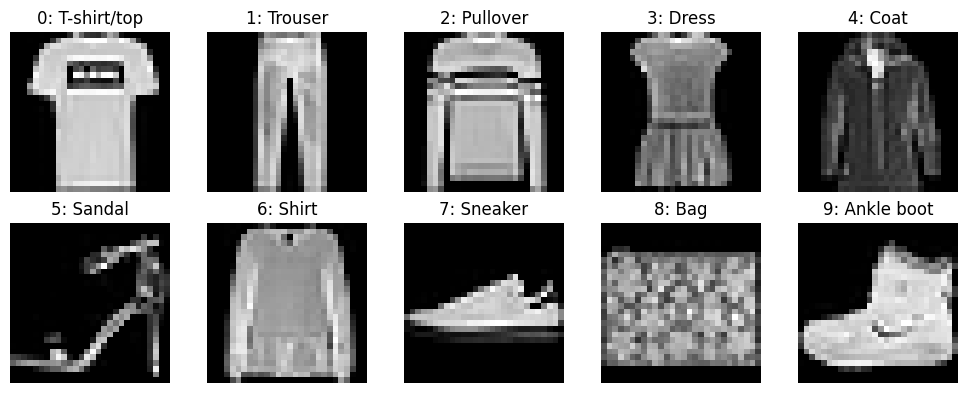

In [13]:
# Contoh gambar dari masing-masing kelas

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
shown = set()

for img, label in raw_train:
    if label not in shown:
        ax = axes[label // 5, label % 5]
        ax.imshow(img.squeeze(), cmap="gray")
        ax.set_title(f"{label}: {classes[label]}")
        ax.axis("off")
        shown.add(label)
    if len(shown) == 10:
        break

plt.tight_layout()
plt.show()

### Eksperimen MLP Classifier

In [15]:
# enc & head dipisah agar lebih mudah ambil z_mlp dan bobotnya
mlp_enc = nn.Sequential(
    nn.Linear(784, 256),
    nn.ReLU(),
    nn.Linear(256, 64),
    nn.ReLU()
).to(device)

mlp_head = nn.Linear(64, 10).to(device)

loss_fn = nn.CrossEntropyLoss()
opt = optim.Adam(list(mlp_enc.parameters()) + list(mlp_head.parameters()), lr=1e-3)

epochs = 14
for epoch in range(epochs):
    mlp_enc.train()
    mlp_head.train()
    total_loss = 0

    for imgs, labels in train_loader:
        x = imgs.view(imgs.size(0), -1).to(device)
        y = labels.to(device)

        opt.zero_grad()
        z = mlp_enc(x)
        out = mlp_head(z)
        loss = loss_fn(out, y)
        loss.backward()
        opt.step()
        total_loss += loss.item()

    mlp_enc.eval()
    mlp_head.eval()
    correct, total = 0, 0


    with torch.no_grad():
        for imgs, labels in val_loader:
            x = imgs.view(imgs.size(0), -1).to(device)
            y = labels.to(device)
            preds = mlp_head(mlp_enc(x)).argmax(dim=1)
            correct += (preds == y).sum().item()
            total += y.size(0)

    val_acc = 100 * correct / total
    print(f"Epoch {epoch+1:02d}/{epochs} | Loss: {total_loss/len(train_loader):.4f} | Val Acc: {val_acc:.2f}%")

Epoch 01/14 | Loss: 0.6040 | Val Acc: 81.61%
Epoch 02/14 | Loss: 0.4049 | Val Acc: 83.91%
Epoch 03/14 | Loss: 0.3611 | Val Acc: 85.73%
Epoch 04/14 | Loss: 0.3338 | Val Acc: 86.59%
Epoch 05/14 | Loss: 0.3169 | Val Acc: 87.21%
Epoch 06/14 | Loss: 0.2984 | Val Acc: 87.76%
Epoch 07/14 | Loss: 0.2828 | Val Acc: 87.47%
Epoch 08/14 | Loss: 0.2708 | Val Acc: 88.04%
Epoch 09/14 | Loss: 0.2589 | Val Acc: 88.36%
Epoch 10/14 | Loss: 0.2475 | Val Acc: 88.74%
Epoch 11/14 | Loss: 0.2410 | Val Acc: 88.86%
Epoch 12/14 | Loss: 0.2309 | Val Acc: 88.43%
Epoch 13/14 | Loss: 0.2224 | Val Acc: 88.84%
Epoch 14/14 | Loss: 0.2131 | Val Acc: 89.23%


In [16]:
correct, total = 0, 0
with torch.no_grad():
    for imgs, labels in test_loader:
        x = imgs.view(imgs.size(0), -1).to(device)
        y = labels.to(device)
        preds = mlp_head(mlp_enc(x)).argmax(dim=1)
        correct += (preds == y).sum().item()
        total += y.size(0)

test_acc = 100 * correct / total
print(f"Test Accuracy MLP: {test_acc:.2f}%")

Test Accuracy MLP: 89.40%


In [17]:
torch.save(mlp_enc.state_dict(), "outputs/models/mlp_enc.pt")
torch.save(mlp_head.state_dict(), "outputs/models/mlp_head.pt")

In [18]:
mlp_enc.eval()
mlp_head.eval()

W1 = mlp_enc[0].weight.detach()
W2 = mlp_enc[2].weight.detach()
W3 = mlp_head.weight.detach()

print("Shape bobot W1:", W1.shape)
print("Shape bobot W2:", W2.shape)
print("Shape bobot W3:", W3.shape)

Shape bobot W1: torch.Size([256, 784])
Shape bobot W2: torch.Size([64, 256])
Shape bobot W3: torch.Size([10, 64])


In [19]:
eye64 = torch.eye(64, device=device)
ortho_err = (W3.T @ W3 - eye64).abs().max().item()
print(f"{ortho_err:.4f}")

1.4733


###  Top-Down Weight Transposition

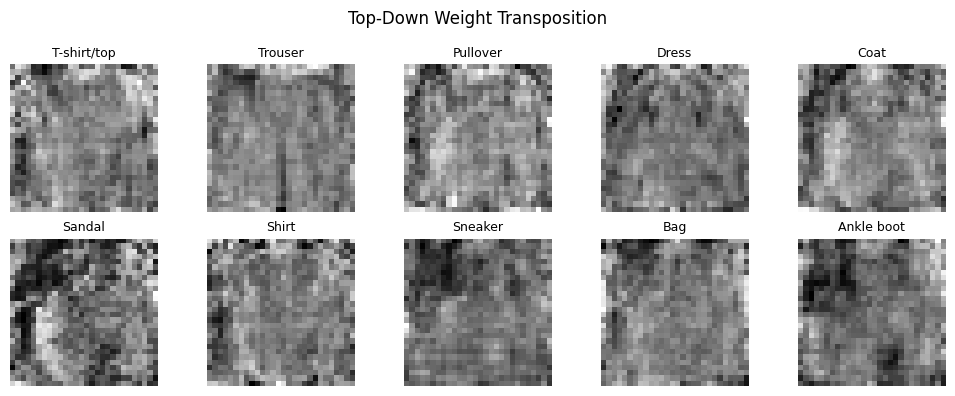

In [20]:
y_onehot = torch.eye(10, device=device)
z_hat = F.relu(y_onehot @ W3)
h1_hat = F.relu(z_hat @ W2)
x_from_y = torch.sigmoid(h1_hat @ W1).view(10, 28, 28).cpu()

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i in range(10):
    ax = axes[i // 5, i % 5]
    ax.imshow(x_from_y[i], cmap="gray")
    ax.set_title(classes[i], fontsize=9)
    ax.axis("off")
plt.suptitle("Top-Down Weight Transposition")
plt.tight_layout()
plt.show()

### Latent Transpose Projection

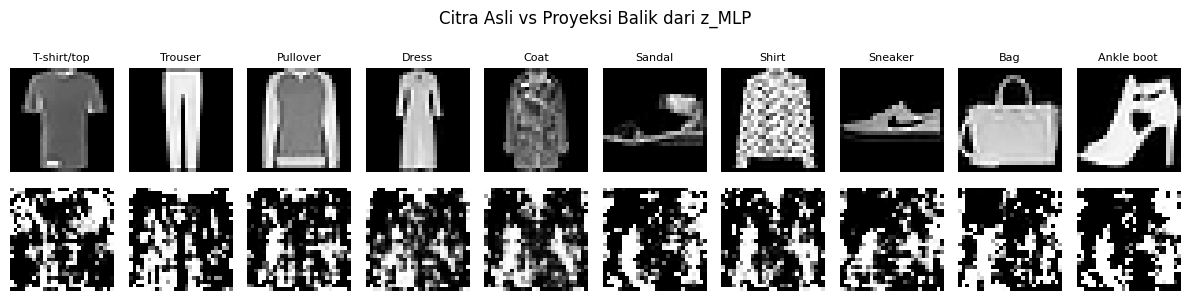

In [21]:
picked_imgs = {}
for img, label in test_data:
    if label not in picked_imgs:
        picked_imgs[label] = img
    if len(picked_imgs) == 10:
        break

sample_imgs = torch.stack([picked_imgs[i] for i in range(10)])
sample_labels = list(range(10))
x_real = sample_imgs.view(10, -1).to(device)

with torch.no_grad():
    z_sample = mlp_enc(x_real)
    x_from_z = torch.sigmoid(F.relu(z_sample @ W2) @ W1).view(10, 28, 28).cpu()

fig, axes = plt.subplots(2, 10, figsize=(12, 3.2))
for i in range(10):
    axes[0, i].imshow(sample_imgs[i].squeeze(), cmap="gray")
    axes[0, i].set_title(classes[sample_labels[i]], fontsize=8)
    axes[0, i].axis("off")

    axes[1, i].imshow(x_from_z[i], cmap="gray")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Asli", fontsize=10)
axes[1, 0].set_ylabel("W^T (z_MLP)", fontsize=10)
plt.suptitle("Citra Asli vs Proyeksi Balik dari z_MLP")
plt.tight_layout()
plt.show()

### Frozen Latent Decoding

In [22]:
# Freeze seluruh bobot MLP Classifier
for p in mlp_enc.parameters():
    p.requires_grad = False
for p in mlp_head.parameters():
    p.requires_grad = False
mlp_enc.eval()

# Decoder terpisah (64 -> 256 -> 784)
frozen_dec = nn.Sequential(
    nn.Linear(64, 256),
    nn.ReLU(),
    nn.Linear(256, 784),
    nn.Sigmoid()
).to(device)

mse_fn = nn.MSELoss()
dec_opt = optim.Adam(frozen_dec.parameters(), lr=1e-3)

dec_epochs = 15
for epoch in range(dec_epochs):
    frozen_dec.train()
    total_loss = 0

    for imgs, _ in train_loader:
        x = imgs.view(imgs.size(0), -1).to(device)
        with torch.no_grad():
            z_mlp = mlp_enc(x)

        dec_opt.zero_grad()
        recon = frozen_dec(z_mlp)
        loss = mse_fn(recon, x)
        loss.backward()
        dec_opt.step()
        total_loss += loss.item()

    print(f"Epoch {epoch+1:02d}/{dec_epochs} | Train MSE: {total_loss/len(train_loader):.4f}")

Epoch 01/15 | Train MSE: 0.0361
Epoch 02/15 | Train MSE: 0.0246
Epoch 03/15 | Train MSE: 0.0222
Epoch 04/15 | Train MSE: 0.0209
Epoch 05/15 | Train MSE: 0.0202
Epoch 06/15 | Train MSE: 0.0196
Epoch 07/15 | Train MSE: 0.0191
Epoch 08/15 | Train MSE: 0.0187
Epoch 09/15 | Train MSE: 0.0184
Epoch 10/15 | Train MSE: 0.0182
Epoch 11/15 | Train MSE: 0.0179
Epoch 12/15 | Train MSE: 0.0178
Epoch 13/15 | Train MSE: 0.0176
Epoch 14/15 | Train MSE: 0.0174
Epoch 15/15 | Train MSE: 0.0173


In [23]:
psnr_metric = PeakSignalNoiseRatio(data_range=1.0).to(device)
ssim_metric = StructuralSimilarityIndexMeasure(data_range=1.0).to(device)

frozen_dec.eval()
mse_sum = 0.0
total_pixels = 0

with torch.no_grad():
    for imgs, _ in test_loader:
        x_img = imgs.to(device)
        x_flat = x_img.view(x_img.size(0), -1)
        recon_img = frozen_dec(mlp_enc(x_flat)).view(-1, 1, 28, 28)

        mse_sum += F.mse_loss(recon_img, x_img, reduction="sum").item()
        total_pixels += x_img.numel()
        psnr_metric.update(recon_img, x_img)
        ssim_metric.update(recon_img, x_img)

mlp_dec_mse = mse_sum / total_pixels
mlp_dec_psnr = psnr_metric.compute().item()
mlp_dec_ssim = ssim_metric.compute().item()

print(f"Test MSE: {mlp_dec_mse:.5f}")
print(f"PSNR: {mlp_dec_psnr:.2f} dB")
print(f"SSIM: {mlp_dec_ssim:.4f}")

Test MSE: 0.01735
PSNR: 17.61 dB
SSIM: 0.7016


In [24]:
torch.save(mlp_enc.state_dict(), "outputs/models/mlp_enc.pt")
torch.save(mlp_head.state_dict(), "outputs/models/mlp_head.pt")
torch.save(frozen_dec.state_dict(), "outputs/models/frozen_dec.pt")

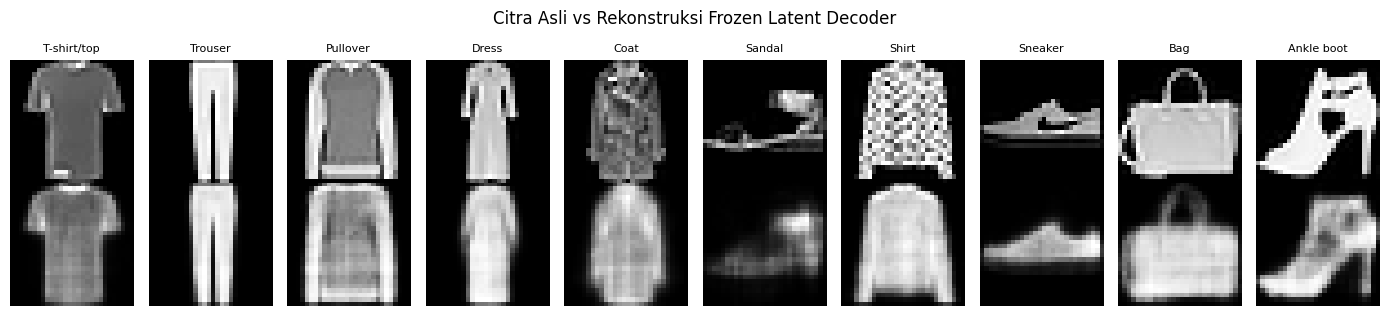

In [25]:
with torch.no_grad():
    x_frozen = frozen_dec(mlp_enc(x_real)).view(10, 28, 28).cpu()

fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for i in range(10):
    axes[0, i].imshow(sample_imgs[i].squeeze(), cmap="gray")
    axes[0, i].set_title(classes[sample_labels[i]], fontsize=8)
    axes[0, i].axis("off")

    axes[1, i].imshow(x_frozen[i], cmap="gray")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Asli", fontsize=10)
axes[1, 0].set_ylabel("Frozen Dec", fontsize=10)
plt.suptitle("Citra Asli vs Rekonstruksi Frozen Latent Decoder")
plt.tight_layout()
plt.show()

###  Uji Sampling Generatif pada Ruang Laten MLP Classifier

In [26]:
z_list = []

with torch.no_grad():
    for imgs, _ in test_loader:
        x = imgs.view(imgs.size(0), -1).to(device)
        z_list.append(mlp_enc(x))

all_z_mlp = torch.cat(z_list, dim=0)

mu_z = all_z_mlp.mean(dim=0)
std_z = all_z_mlp.std(dim=0)
zero_pct = (all_z_mlp == 0).float().mean().item() * 100
print(f"Mean range: [{mu_z.min():.2f}, {mu_z.max():.2f}]")
print(f"Std range: [{std_z.min():.2f}, {std_z.max():.2f}]")
print(f"Elemen bernilai 0: {zero_pct:.1f}%")

Mean range: [0.00, 3.30]
Std range: [0.00, 5.20]
Elemen bernilai 0: 45.3%


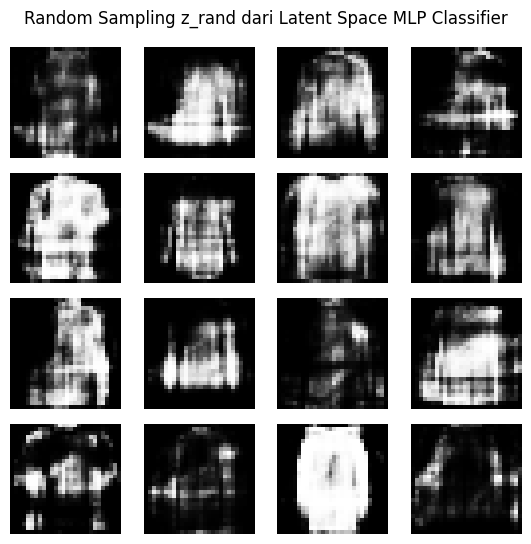

In [27]:
z_rand = mu_z + std_z * torch.randn(16, 64, device=device)

with torch.no_grad():
    x_rand = frozen_dec(z_rand).view(16, 28, 28).cpu()

fig, axes = plt.subplots(4, 4, figsize=(5.5, 5.5))

for i in range(16):
    ax = axes[i // 4, i % 4]
    ax.imshow(x_rand[i], cmap="gray")
    ax.axis("off")
plt.suptitle("Random Sampling z_rand dari Latent Space MLP Classifier")
plt.tight_layout()
plt.show()

## Vanilla Autoencoder

In [28]:
ae_enc = nn.Sequential(
    nn.Linear(784, 256),
    nn.ReLU(),
    nn.Linear(256, 64)
).to(device)

ae_dec = nn.Sequential(
    nn.Linear(64, 256),
    nn.ReLU(),
    nn.Linear(256, 784),
    nn.Sigmoid()
).to(device)

ae_opt = optim.Adam(list(ae_enc.parameters()) + list(ae_dec.parameters()), lr=1e-3)

ae_epochs = 20
ae_losses = []
ae_time = []

for epoch in range(ae_epochs):
    t_start = time.time()
    ae_enc.train()
    ae_dec.train()
    train_loss = 0.0

    for imgs, _ in train_loader:
        x = imgs.view(imgs.size(0), -1).to(device)

        ae_opt.zero_grad()
        recon = ae_dec(ae_enc(x))
        loss = mse_fn(recon, x)
        loss.backward()
        ae_opt.step()
        train_loss += loss.item()

    # Cek validation loss
    ae_enc.eval()
    ae_dec.eval()
    val_loss = 0.0
    with torch.no_grad():
        for imgs, _ in val_loader:
            x = imgs.view(imgs.size(0), -1).to(device)
            val_loss += mse_fn(ae_dec(ae_enc(x)), x).item()

    ep_time = time.time() - t_start
    avg_train = train_loss / len(train_loader)
    avg_val = val_loss / len(val_loader)

    ae_losses.append(avg_train)
    ae_time.append(ep_time)
    print(f"Epoch {epoch+1:02d}/{ae_epochs} | Train MSE: {avg_train:.5f} | Val MSE: {avg_val:.5f} | Time: {ep_time:.2f}s")

Epoch 01/20 | Train MSE: 0.03269 | Val MSE: 0.01939 | Time: 10.34s
Epoch 02/20 | Train MSE: 0.01707 | Val MSE: 0.01533 | Time: 11.58s
Epoch 03/20 | Train MSE: 0.01420 | Val MSE: 0.01330 | Time: 10.38s
Epoch 04/20 | Train MSE: 0.01264 | Val MSE: 0.01217 | Time: 10.92s
Epoch 05/20 | Train MSE: 0.01152 | Val MSE: 0.01114 | Time: 10.81s
Epoch 06/20 | Train MSE: 0.01068 | Val MSE: 0.01055 | Time: 10.69s
Epoch 07/20 | Train MSE: 0.01008 | Val MSE: 0.00992 | Time: 9.04s
Epoch 08/20 | Train MSE: 0.00960 | Val MSE: 0.00948 | Time: 8.92s
Epoch 09/20 | Train MSE: 0.00919 | Val MSE: 0.00914 | Time: 9.46s
Epoch 10/20 | Train MSE: 0.00882 | Val MSE: 0.00888 | Time: 11.01s
Epoch 11/20 | Train MSE: 0.00850 | Val MSE: 0.00855 | Time: 11.11s
Epoch 12/20 | Train MSE: 0.00826 | Val MSE: 0.00830 | Time: 10.30s
Epoch 13/20 | Train MSE: 0.00804 | Val MSE: 0.00809 | Time: 9.54s
Epoch 14/20 | Train MSE: 0.00781 | Val MSE: 0.00790 | Time: 8.55s
Epoch 15/20 | Train MSE: 0.00763 | Val MSE: 0.00772 | Time: 8.10s
E

In [29]:
torch.save(ae_enc.state_dict(), "outputs/models/ae_enc.pt")
torch.save(ae_dec.state_dict(), "outputs/models/ae_dec.pt")
np.save("outputs/models/ae_losses.npy", np.array(ae_losses))

In [30]:
# Reset metric yang dipakai ulang dari cell MLP
psnr_metric.reset()
ssim_metric.reset()

In [31]:
ae_enc.eval()
ae_dec.eval()
mse_sum = 0.0
total_pixels = 0

with torch.no_grad():

    for imgs, _ in test_loader:
        x_img = imgs.to(device)
        x_flat = x_img.view(x_img.size(0), -1)
        recon_img = ae_dec(ae_enc(x_flat)).view(-1, 1, 28, 28)

        mse_sum += F.mse_loss(recon_img, x_img, reduction="sum").item()
        total_pixels += x_img.numel()
        psnr_metric.update(recon_img, x_img)
        ssim_metric.update(recon_img, x_img)

ae_mse = mse_sum / total_pixels
ae_psnr = psnr_metric.compute().item()
ae_ssim = ssim_metric.compute().item()
ae_avg_time = np.mean(ae_time)

# Inference Latency per batch 64 sampel
x_64 = next(iter(test_loader))[0][:64].view(64, -1).to(device)

with torch.no_grad():

    for _ in range(10):
        _ = ae_dec(ae_enc(x_64))
    if device.type == "cuda":
        torch.cuda.synchronize()

    t0 = time.time()

    for _ in range(100):
        _ = ae_dec(ae_enc(x_64))
    if device.type == "cuda":
        torch.cuda.synchronize()

    ae_latency = ((time.time() - t0) / 100) * 1000  # dalam ms

print("=== Evaluasi Vanilla AE ===")
print(f"Dimensi Laten: 64")
print(f"Training Time/Epoch: {ae_avg_time:.2f} detik")
print(f"Latency: {ae_latency:.3f} ms")
print(f"Test MSE: {ae_mse:.5f}")
print(f"Test PSNR: {ae_psnr:.2f} dB")
print(f"Test SSIM: {ae_ssim:.4f}")
print("FID Score: N/A (Latent Voids)")

=== Evaluasi Vanilla AE ===
Dimensi Laten: 64
Training Time/Epoch: 9.73 detik
Latency: 0.182 ms
Test MSE: 0.00710
Test PSNR: 21.49 dB
Test SSIM: 0.8525
FID Score: N/A (Latent Voids)


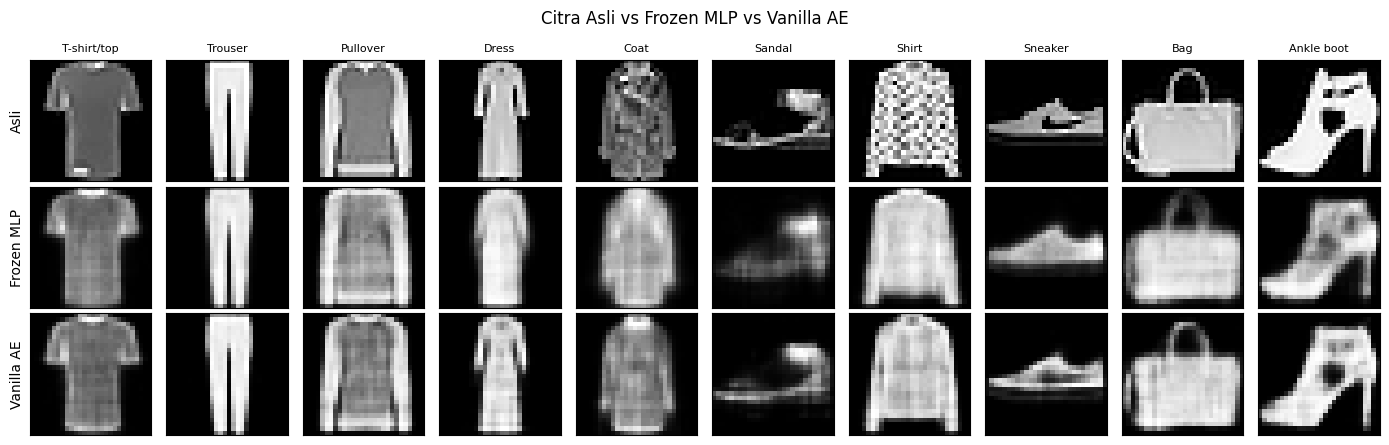

In [32]:
with torch.no_grad():
    x_ae = ae_dec(ae_enc(x_real)).view(10, 28, 28).cpu()

fig, axes = plt.subplots(3, 10, figsize=(14, 4.5))
for i in range(10):
    axes[0, i].imshow(sample_imgs[i].squeeze(), cmap="gray")
    axes[0, i].set_title(classes[sample_labels[i]], fontsize=8)
    axes[0, i].set_xticks([])
    axes[0, i].set_yticks([])

    axes[1, i].imshow(x_frozen[i], cmap="gray")
    axes[1, i].set_xticks([])
    axes[1, i].set_yticks([])

    axes[2, i].imshow(x_ae[i], cmap="gray")
    axes[2, i].set_xticks([])
    axes[2, i].set_yticks([])

axes[0, 0].set_ylabel("Asli", fontsize=10)
axes[1, 0].set_ylabel("Frozen MLP", fontsize=10)
axes[2, 0].set_ylabel("Vanilla AE", fontsize=10)
plt.suptitle("Citra Asli vs Frozen MLP vs Vanilla AE")
plt.tight_layout()
plt.show()

## Sparse Autoencoder

In [33]:
sae_enc = nn.Sequential(
    nn.Linear(784, 256),
    nn.ReLU(),
    nn.Linear(256, 64),
    nn.ReLU()
).to(device)

sae_dec = nn.Sequential(
    nn.Linear(64, 256),
    nn.ReLU(),
    nn.Linear(256, 784),
    nn.Sigmoid()
).to(device)

sae_opt = optim.Adam(list(sae_enc.parameters()) + list(sae_dec.parameters()), lr=1e-3)

lam = 1e-4  # bobot penalti sparsity
sae_epochs = 20
sae_losses = []
sae_time = []

for epoch in range(sae_epochs):

    t_start = time.time()
    sae_enc.train()
    sae_dec.train()
    train_loss = 0.0

    for imgs, _ in train_loader:
        x = imgs.view(imgs.size(0), -1).to(device)

        sae_opt.zero_grad()
        h = sae_enc(x)
        recon = sae_dec(h)

        recon_loss = mse_fn(recon, x)
        l1_penalty = h.abs().sum(dim=1).mean()
        loss = recon_loss + lam * l1_penalty

        loss.backward()
        sae_opt.step()
        train_loss += loss.item()

    sae_enc.eval()
    sae_dec.eval()
    val_mse = 0.0
    with torch.no_grad():
        for imgs, _ in val_loader:
            x = imgs.view(imgs.size(0), -1).to(device)
            val_mse += mse_fn(sae_dec(sae_enc(x)), x).item()

    ep_time = time.time() - t_start
    avg_train = train_loss / len(train_loader)
    avg_val = val_mse / len(val_loader)

    sae_losses.append(avg_train)
    sae_time.append(ep_time)
    print(f"Epoch {epoch+1:02d}/{sae_epochs} | Train Loss: {avg_train:.5f} | Val MSE: {avg_val:.5f} | Time: {ep_time:.2f}s")

Epoch 01/20 | Train Loss: 0.03756 | Val MSE: 0.02036 | Time: 9.09s
Epoch 02/20 | Train Loss: 0.01999 | Val MSE: 0.01682 | Time: 9.70s
Epoch 03/20 | Train Loss: 0.01731 | Val MSE: 0.01495 | Time: 7.67s
Epoch 04/20 | Train Loss: 0.01584 | Val MSE: 0.01393 | Time: 8.87s
Epoch 05/20 | Train Loss: 0.01480 | Val MSE: 0.01302 | Time: 11.07s
Epoch 06/20 | Train Loss: 0.01402 | Val MSE: 0.01241 | Time: 10.90s
Epoch 07/20 | Train Loss: 0.01341 | Val MSE: 0.01203 | Time: 11.33s
Epoch 08/20 | Train Loss: 0.01291 | Val MSE: 0.01151 | Time: 11.82s
Epoch 09/20 | Train Loss: 0.01249 | Val MSE: 0.01118 | Time: 8.61s
Epoch 10/20 | Train Loss: 0.01214 | Val MSE: 0.01101 | Time: 11.26s
Epoch 11/20 | Train Loss: 0.01186 | Val MSE: 0.01075 | Time: 10.98s
Epoch 12/20 | Train Loss: 0.01159 | Val MSE: 0.01051 | Time: 8.82s
Epoch 13/20 | Train Loss: 0.01138 | Val MSE: 0.01027 | Time: 8.15s
Epoch 14/20 | Train Loss: 0.01117 | Val MSE: 0.01015 | Time: 9.21s
Epoch 15/20 | Train Loss: 0.01101 | Val MSE: 0.01004 | T

In [34]:
torch.save(sae_enc.state_dict(), "outputs/models/sae_enc.pt")
torch.save(sae_dec.state_dict(), "outputs/models/sae_dec.pt")
np.save("outputs/models/sae_losses.npy", np.array(sae_losses))

In [35]:
# Reset metric
psnr_metric.reset()
ssim_metric.reset()

In [36]:
sae_enc.eval()
sae_dec.eval()
ae_enc.eval()

mse_sum = 0.0
total_pixels = 0
sae_h_list = []
ae_z_list = []

with torch.no_grad():
    for imgs, _ in test_loader:
        x_img = imgs.to(device)
        x_flat = x_img.view(x_img.size(0), -1)

        h = sae_enc(x_flat)
        recon_img = sae_dec(h).view(-1, 1, 28, 28)

        mse_sum += F.mse_loss(recon_img, x_img, reduction="sum").item()
        total_pixels += x_img.numel()
        psnr_metric.update(recon_img, x_img)
        ssim_metric.update(recon_img, x_img)

        sae_h_list.append(h)
        ae_z_list.append(ae_enc(x_flat))

sae_mse = mse_sum / total_pixels
sae_psnr = psnr_metric.compute().item()
sae_ssim = ssim_metric.compute().item()
sae_avg_time = np.mean(sae_time)

# Sparsity Sparse AE vs Vanilla AE
all_h = torch.cat(sae_h_list, dim=0)
all_z = torch.cat(ae_z_list, dim=0)

sae_zero = (all_h == 0).float().mean().item() * 100
sae_near_zero = (all_h.abs() < 0.05).float().mean().item() * 100
ae_near_zero = (all_z.abs() < 0.05).float().mean().item() * 100
sae_l1 = all_h.abs().sum(dim=1).mean().item()
ae_l1 = all_z.abs().sum(dim=1).mean().item()

# Inference latency per batch 64
with torch.no_grad():

    for _ in range(10):
        _ = sae_dec(sae_enc(x_64))
    if device.type == "cuda":
        torch.cuda.synchronize()

    t0 = time.time()

    for _ in range(100):
        _ = sae_dec(sae_enc(x_64))
    if device.type == "cuda":
        torch.cuda.synchronize()
    sae_latency = ((time.time() - t0) / 100) * 1000

print("=== Evaluasi Sparse AE ===")
print("Dimensi Laten: 64")
print(f"Lambda L1: {lam}")
print(f"Training Time/Epoch: {sae_avg_time:.2f} detik")
print(f"Latency: {sae_latency:.3f} ms")
print(f"Test MSE: {sae_mse:.5f}")
print(f"Test PSNR: {sae_psnr:.2f} dB")
print(f"Test SSIM: {sae_ssim:.4f}")
print("FID Score: N/A (Latent Voids)")

=== Evaluasi Sparse AE ===
Dimensi Laten: 64
Lambda L1: 0.0001
Training Time/Epoch: 9.45 detik
Latency: 0.170 ms
Test MSE: 0.00943
Test PSNR: 20.26 dB
Test SSIM: 0.8094
FID Score: N/A (Latent Voids)


In [37]:
print(f"Sparse AE aktivasi tepat 0: {sae_zero:.1f}%")
print(f"Sparse AE hampir 0 (<0.05): {sae_near_zero:.1f}%")
print(f"Vanilla AE hampir 0 (<0.05): {ae_near_zero:.1f}%")
print(f"Rata-rata ||h||_1 Sparse AE: {sae_l1:.2f}")
print(f"Rata-rata ||z||_1 Vanilla AE: {ae_l1:.2f}")

Sparse AE aktivasi tepat 0: 48.6%
Sparse AE hampir 0 (<0.05): 54.0%
Vanilla AE hampir 0 (<0.05): 2.8%
Rata-rata ||h||_1 Sparse AE: 9.40
Rata-rata ||z||_1 Vanilla AE: 78.39


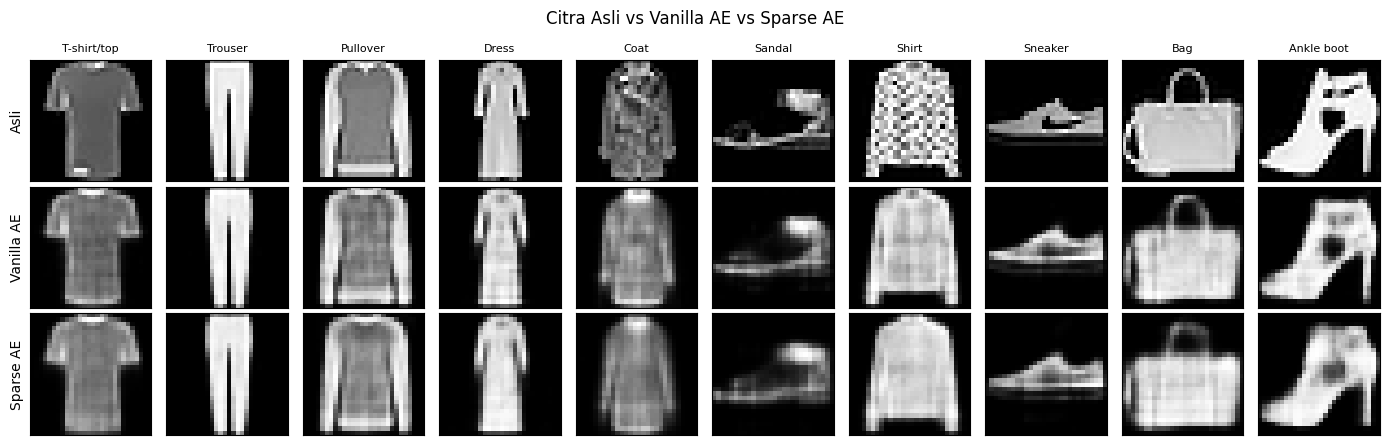

In [38]:
with torch.no_grad():
    x_sae = sae_dec(sae_enc(x_real)).view(10, 28, 28).cpu()

fig, axes = plt.subplots(3, 10, figsize=(14, 4.5))
for i in range(10):
    axes[0, i].imshow(sample_imgs[i].squeeze(), cmap="gray")
    axes[0, i].set_title(classes[sample_labels[i]], fontsize=8)
    axes[0, i].set_xticks([])
    axes[0, i].set_yticks([])

    axes[1, i].imshow(x_ae[i], cmap="gray")
    axes[1, i].set_xticks([])
    axes[1, i].set_yticks([])

    axes[2, i].imshow(x_sae[i], cmap="gray")
    axes[2, i].set_xticks([])
    axes[2, i].set_yticks([])

axes[0, 0].set_ylabel("Asli", fontsize=10)
axes[1, 0].set_ylabel("Vanilla AE", fontsize=10)
axes[2, 0].set_ylabel("Sparse AE", fontsize=10)
plt.suptitle("Citra Asli vs Vanilla AE vs Sparse AE")
plt.tight_layout()
plt.show()

## Variational Autoencoder (VAE)

In [39]:
vae_enc = nn.Sequential(
    nn.Linear(784, 256),
    nn.ReLU()
).to(device)

vae_mu = nn.Linear(256, 64).to(device)
vae_logvar = nn.Linear(256, 64).to(device)

vae_dec = nn.Sequential(
    nn.Linear(64, 256),
    nn.ReLU(),
    nn.Linear(256, 784),
    nn.Sigmoid()
).to(device)

vae_params = (
    list(vae_enc.parameters()) +
    list(vae_mu.parameters()) +
    list(vae_logvar.parameters()) +
    list(vae_dec.parameters())
)
vae_opt = optim.Adam(vae_params, lr=1e-3)

vae_epochs = 20
vae_losses = []
vae_time = []

for epoch in range(vae_epochs):
    t_start = time.time()
    vae_enc.train()
    vae_mu.train()
    vae_logvar.train()
    vae_dec.train()

    train_loss = 0.0

    for imgs, _ in train_loader:
        x = imgs.view(imgs.size(0), -1).to(device)

        vae_opt.zero_grad()
        h = vae_enc(x)
        mu = vae_mu(h)
        logvar = vae_logvar(h)

        std = torch.exp(0.5 * logvar)
        z = mu + std * torch.randn_like(std)
        recon = vae_dec(z)


        bce = F.binary_cross_entropy(recon, x, reduction="sum") / x.size(0)
        kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / x.size(0)
        loss = bce + kl

        loss.backward()
        vae_opt.step()
        train_loss += loss.item()

    vae_enc.eval(); vae_mu.eval(); vae_logvar.eval(); vae_dec.eval()
    val_loss = 0.0
    with torch.no_grad():
        for imgs, _ in val_loader:
            x = imgs.view(imgs.size(0), -1).to(device)
            h = vae_enc(x)
            mu = vae_mu(h)
            logvar = vae_logvar(h)
            z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)
            recon = vae_dec(z)

            bce = F.binary_cross_entropy(recon, x, reduction="sum") / x.size(0)
            kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / x.size(0)
            val_loss += (bce + kl).item()

    ep_time = time.time() - t_start
    avg_train = train_loss / len(train_loader)
    avg_val = val_loss / len(val_loader)

    vae_losses.append(avg_train)
    vae_time.append(ep_time)
    print(f"Epoch {epoch+1:02d}/{vae_epochs} | Train Loss: {avg_train:.2f} | Val Loss: {avg_val:.2f} | Time: {ep_time:.2f}s")

Epoch 01/20 | Train Loss: 300.23 | Val Loss: 274.13 | Time: 8.38s
Epoch 02/20 | Train Loss: 267.11 | Val Loss: 262.75 | Time: 8.75s
Epoch 03/20 | Train Loss: 258.06 | Val Loss: 255.67 | Time: 8.84s
Epoch 04/20 | Train Loss: 252.70 | Val Loss: 251.86 | Time: 7.83s
Epoch 05/20 | Train Loss: 249.84 | Val Loss: 249.70 | Time: 8.84s
Epoch 06/20 | Train Loss: 248.10 | Val Loss: 248.21 | Time: 8.74s
Epoch 07/20 | Train Loss: 246.81 | Val Loss: 247.25 | Time: 8.83s
Epoch 08/20 | Train Loss: 245.95 | Val Loss: 246.35 | Time: 8.90s
Epoch 09/20 | Train Loss: 245.21 | Val Loss: 245.76 | Time: 8.03s
Epoch 10/20 | Train Loss: 244.70 | Val Loss: 245.29 | Time: 8.73s
Epoch 11/20 | Train Loss: 244.18 | Val Loss: 244.78 | Time: 8.95s
Epoch 12/20 | Train Loss: 243.69 | Val Loss: 244.19 | Time: 7.99s
Epoch 13/20 | Train Loss: 243.39 | Val Loss: 243.99 | Time: 8.84s
Epoch 14/20 | Train Loss: 243.13 | Val Loss: 243.95 | Time: 8.50s
Epoch 15/20 | Train Loss: 242.83 | Val Loss: 243.46 | Time: 8.54s
Epoch 16/2

In [40]:
torch.save(vae_enc.state_dict(), "outputs/models/vae_enc.pt")
torch.save(vae_mu.state_dict(), "outputs/models/vae_mu.pt")
torch.save(vae_logvar.state_dict(), "outputs/models/vae_logvar.pt")
torch.save(vae_dec.state_dict(), "outputs/models/vae_dec.pt")
np.save("outputs/models/vae_losses.npy", np.array(vae_losses))

In [41]:
# Reset metric
psnr_metric.reset()
ssim_metric.reset()

In [42]:
# Fitur gambar asli cukup dihitung sekali
fid_metric = FrechetInceptionDistance(feature=2048, reset_real_features=False).to(device)

vae_enc.eval()
vae_mu.eval()
vae_logvar.eval()
vae_dec.eval()

mse_sum = 0.0
total_pixels = 0

with torch.no_grad():
    for imgs, _ in test_loader:
        x_img = imgs.to(device)
        x_flat = x_img.view(x_img.size(0), -1)

        mu = vae_mu(vae_enc(x_flat))
        recon_img = vae_dec(mu).view(-1, 1, 28, 28)

        mse_sum += F.mse_loss(recon_img, x_img, reduction="sum").item()
        total_pixels += x_img.numel()
        psnr_metric.update(recon_img, x_img)
        ssim_metric.update(recon_img, x_img)

        real_rgb = (x_img.clamp(0, 1) * 255).to(torch.uint8).repeat(1, 3, 1, 1)
        fid_metric.update(real_rgb, real=True)

vae_mse = mse_sum / total_pixels
vae_psnr = psnr_metric.compute().item()
vae_ssim = ssim_metric.compute().item()
vae_avg_time = np.mean(vae_time)

# Generate sample baru untuk hitung FID Score
torch.manual_seed(seed)
n_total = len(test_data)
n_done = 0
with torch.no_grad():
    while n_done < n_total:
        bs = min(128, n_total - n_done)
        z_rand = torch.randn(bs, 64, device=device)
        fake_img = vae_dec(z_rand).view(-1, 1, 28, 28)
        fake_rgb = (fake_img.clamp(0, 1) * 255).to(torch.uint8).repeat(1, 3, 1, 1)
        fid_metric.update(fake_rgb, real=False)
        n_done += bs

vae_fid = fid_metric.compute().item()

# Inference Latency single-pass decoder
z_64 = torch.randn(64, 64, device=device)

with torch.no_grad():
    for _ in range(10):
        _ = vae_dec(z_64)
    if device.type == "cuda":
        torch.cuda.synchronize()

    t0 = time.time()

    for _ in range(100):
        _ = vae_dec(z_64)
    if device.type == "cuda":
        torch.cuda.synchronize()
    vae_latency = ((time.time() - t0) / 100) * 1000

print("=== Evaluasi VAE ===")
print("Dimensi Laten: 64")
print(f"Training Time/Epoch: {vae_avg_time:.2f} detik")
print(f"Latency: {vae_latency:.3f} ms")
print(f"Test MSE: {vae_mse:.5f}")
print(f"Test PSNR: {vae_psnr:.2f} dB")
print(f"Test SSIM: {vae_ssim:.4f}")
print(f"FID Score: {vae_fid:.2f}")

=== Evaluasi VAE ===
Dimensi Laten: 64
Training Time/Epoch: 8.56 detik
Latency: 0.083 ms
Test MSE: 0.01364
Test PSNR: 18.65 dB
Test SSIM: 0.7585
FID Score: 90.79


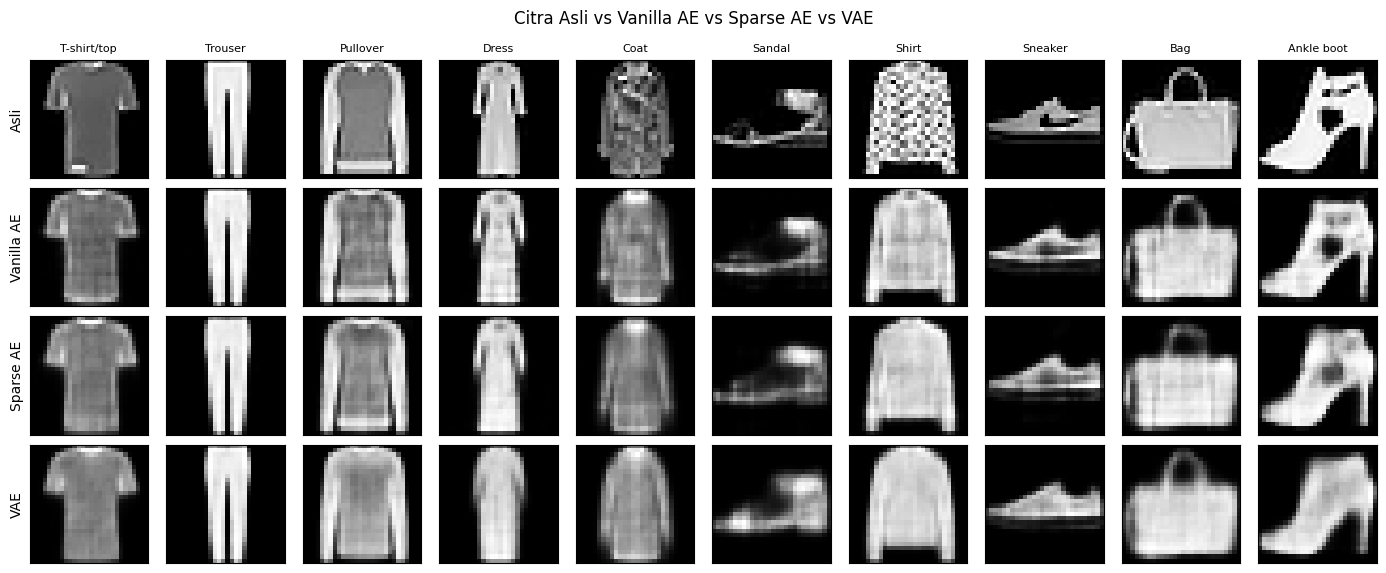

In [43]:
with torch.no_grad():
    x_vae = vae_dec(vae_mu(vae_enc(x_real))).view(10, 28, 28).cpu()

fig, axes = plt.subplots(4, 10, figsize=(14, 5.8))
rows = [sample_imgs.squeeze(), x_ae, x_sae, x_vae]
row_names = ["Asli", "Vanilla AE", "Sparse AE", "VAE"]

for r in range(4):
    for c in range(10):
        axes[r, c].imshow(rows[r][c], cmap="gray")
        if r == 0:
            axes[r, c].set_title(classes[sample_labels[c]], fontsize=8)
        axes[r, c].set_xticks([])
        axes[r, c].set_yticks([])
    axes[r, 0].set_ylabel(row_names[r], fontsize=10)

plt.suptitle("Citra Asli vs Vanilla AE vs Sparse AE vs VAE")
plt.tight_layout()
plt.show()

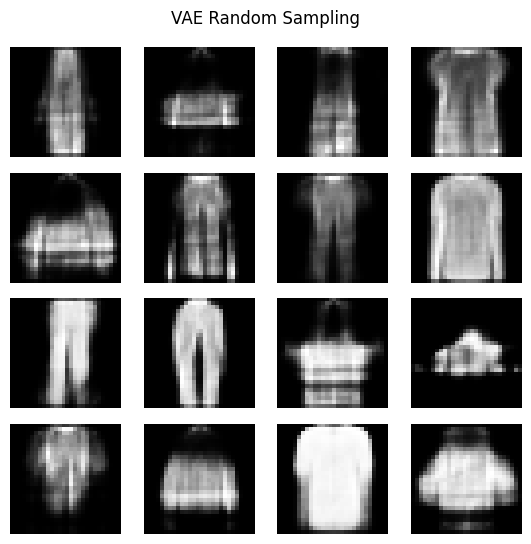

In [44]:
with torch.no_grad():
    z_16 = torch.randn(16, 64, device=device)
    vae_samples = vae_dec(z_16).view(16, 28, 28).cpu()

fig, axes = plt.subplots(4, 4, figsize=(5.5, 5.5))
for i in range(16):
    ax = axes[i // 4, i % 4]
    ax.imshow(vae_samples[i], cmap="gray")
    ax.axis("off")

plt.suptitle("VAE Random Sampling")
plt.tight_layout()
plt.show()

## Generative Adversarial Network (GAN)

In [46]:
z_dim = 100

# Generator
gan_G = nn.Sequential(
    nn.Linear(z_dim, 256),
    nn.LeakyReLU(0.2),
    nn.Linear(256, 512),
    nn.LeakyReLU(0.2),
    nn.Linear(512, 784),
    nn.Tanh()
).to(device)

# Discriminator
gan_D = nn.Sequential(
    nn.Linear(784, 512),
    nn.LeakyReLU(0.2),
    nn.Dropout(0.3),
    nn.Linear(512, 256),
    nn.LeakyReLU(0.2),
    nn.Dropout(0.3),
    nn.Linear(256, 1),
    nn.Sigmoid()
).to(device)

bce_fn = nn.BCELoss()
opt_G = optim.Adam(gan_G.parameters(), lr=2e-4, beta=(0.5, 0.999))
opt_D = optim.Adam(gan_D.parameters(), lr=2e-4, beta=(0.5, 0.999))

gan_epochs = 30
gan_g_losses = []
gan_d_losses = []
gan_time = []

for epoch in range(gan_epochs):
    t_start = time.time()
    gan_G.train()
    gan_D.train()
    d_total = 0.0
    g_total = 0.0

    for imgs, _ in train_loader:
        bs = imgs.size(0)

        real_x = imgs.view(bs, -1).to(device) * 2 - 1
        real_y = torch.ones(bs, 1, device=device)
        fake_y = torch.zeros(bs, 1, device=device)

        # Train Discriminator
        opt_D.zero_grad()
        z = torch.randn(bs, z_dim, device=device)
        fake_x = gan_G(z).detach()

        d_loss_real = bce_fn(gan_D(real_x), real_y)
        d_loss_fake = bce_fn(gan_D(fake_x), fake_y)
        d_loss = d_loss_real + d_loss_fake
        d_loss.backward()
        opt_D.step()

        # Train Generator
        opt_G.zero_grad()
        z = torch.randn(bs, z_dim, device=device)
        gen_x = gan_G(z)
        g_loss = bce_fn(gan_D(gen_x), real_y)
        g_loss.backward()
        opt_G.step()

        d_total += d_loss.item()
        g_total += g_loss.item()

    ep_time = time.time() - t_start
    avg_d = d_total / len(train_loader)
    avg_g = g_total / len(train_loader)

    gan_d_losses.append(avg_d)
    gan_g_losses.append(avg_g)
    gan_time.append(ep_time)
    print(f"Epoch {epoch+1:02d}/{gan_epochs} | D Loss: {avg_d:.4f} | G Loss: {avg_g:.4f} | Time: {ep_time:.2f}s")

Epoch 01/30 | D Loss: 0.6491 | G Loss: 1.7976 | Time: 9.46s
Epoch 02/30 | D Loss: 0.5886 | G Loss: 2.6130 | Time: 8.63s
Epoch 03/30 | D Loss: 0.7677 | G Loss: 2.0988 | Time: 9.11s
Epoch 04/30 | D Loss: 0.8091 | G Loss: 1.8931 | Time: 9.46s
Epoch 05/30 | D Loss: 0.8021 | G Loss: 1.9532 | Time: 8.64s
Epoch 06/30 | D Loss: 0.8510 | G Loss: 1.8080 | Time: 9.18s
Epoch 07/30 | D Loss: 0.8920 | G Loss: 1.7217 | Time: 9.58s
Epoch 08/30 | D Loss: 0.9187 | G Loss: 1.6394 | Time: 8.20s
Epoch 09/30 | D Loss: 0.9352 | G Loss: 1.5842 | Time: 9.27s
Epoch 10/30 | D Loss: 0.9428 | G Loss: 1.5695 | Time: 9.16s
Epoch 11/30 | D Loss: 0.9659 | G Loss: 1.5184 | Time: 8.37s
Epoch 12/30 | D Loss: 0.9905 | G Loss: 1.4587 | Time: 9.31s
Epoch 13/30 | D Loss: 1.0037 | G Loss: 1.4048 | Time: 9.04s
Epoch 14/30 | D Loss: 1.0423 | G Loss: 1.3312 | Time: 8.66s
Epoch 15/30 | D Loss: 1.0480 | G Loss: 1.3034 | Time: 9.23s
Epoch 16/30 | D Loss: 1.0670 | G Loss: 1.2624 | Time: 8.89s
Epoch 17/30 | D Loss: 1.0745 | G Loss: 1

In [47]:
torch.save(gan_G.state_dict(), "outputs/models/gan_G.pt")
torch.save(gan_D.state_dict(), "outputs/models/gan_D.pt")

np.save("outputs/models/gan_g_losses.npy", np.array(gan_g_losses))
np.save("outputs/models/gan_d_losses.npy", np.array(gan_d_losses))

In [ ]:
# Reset metric
fid_metric.reset()

In [48]:
gan_G.eval()

Sequential(
  (0): Linear(in_features=100, out_features=256, bias=True)
  (1): LeakyReLU(negative_slope=0.2)
  (2): Linear(in_features=256, out_features=512, bias=True)
  (3): LeakyReLU(negative_slope=0.2)
  (4): Linear(in_features=512, out_features=784, bias=True)
  (5): Tanh()
)

In [49]:
# Generate sampel baru untuk hitung FID Score
n_total = len(test_data)
n_done = 0

with torch.no_grad():
    while n_done < n_total:
        bs = min(128, n_total - n_done)
        z_rand = torch.randn(bs, z_dim, device=device)


        fake_img = (gan_G(z_rand).view(-1, 1, 28, 28) + 1) / 2
        fake_rgb = (fake_img.clamp(0, 1) * 255).to(torch.uint8).repeat(1, 3, 1, 1)
        fid_metric.update(fake_rgb, real=False)
        n_done += bs

gan_fid = fid_metric.compute().item()
gan_avg_time = np.mean(gan_time)

# inference latency single-pass
z_gan_64 = torch.randn(64, z_dim, device=device)
with torch.no_grad():
    for _ in range(10):
        _ = gan_G(z_gan_64)
    if device.type == "cuda":
        torch.cuda.synchronize()

    t0 = time.time()
    for _ in range(100):
        _ = gan_G(z_gan_64)
    if device.type == "cuda":
        torch.cuda.synchronize()
    gan_latency = ((time.time() - t0) / 100) * 1000

print(" === Evaluasi Vanilla GAN ===")
print("Dimensi Laten: 100 (Prior Noise)")
print(f"Training Time/Epoch: {gan_avg_time:.2f} detik")
print(f"Latency: {gan_latency:.3f} ms")
print("Test MSE: N/A (Tanpa Encoder)")
print("Test PSNR: N/A")
print("Test SSIM: N/A")
print(f"FID Score: {gan_fid:.2f}")

 === Evaluasi Vanilla GAN ===
Dimensi Laten: 100 (Prior Noise)
Training Time/Epoch: 9.01 detik
Latency: 0.128 ms
Test MSE: N/A (Tanpa Encoder)
Test PSNR: N/A
Test SSIM: N/A
FID Score: 131.84


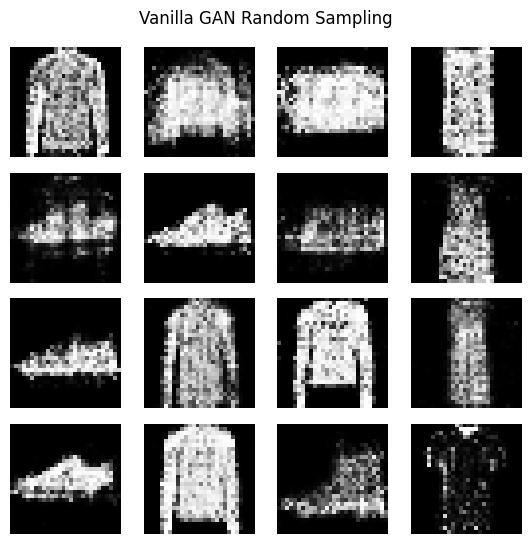

In [50]:
with torch.no_grad():
    z_16 = torch.randn(16, z_dim, device=device)
    gan_samples = ((gan_G(z_16).view(16, 28, 28) + 1) / 2).clamp(0, 1).cpu()

fig, axes = plt.subplots(4, 4, figsize=(5.5, 5.5))
for i in range(16):
    ax = axes[i // 4, i % 4]
    ax.imshow(gan_samples[i], cmap="gray")
    ax.axis("off")

plt.suptitle("Vanilla GAN Random Sampling")
plt.tight_layout()
plt.show()

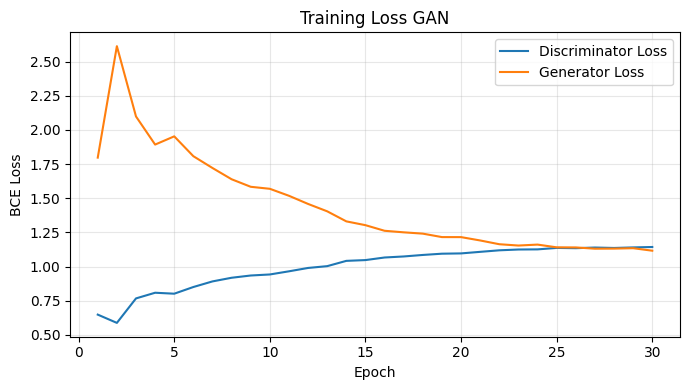

In [52]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, gan_epochs + 1), gan_d_losses, label="Discriminator Loss")
plt.plot(range(1, gan_epochs + 1), gan_g_losses, label="Generator Loss")
plt.xlabel("Epoch")
plt.ylabel("BCE Loss")
plt.title("Training Loss GAN")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Deep Convolutional GAN (DCGAN)

In [63]:
def init_weights(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02)
        nn.init.zeros_(m.bias)

In [64]:
# Generator (ConvTranspose)
dcgan_G = nn.Sequential(
    nn.Unflatten(1, (z_dim, 1, 1)),
    nn.ConvTranspose2d(z_dim, 256, kernel_size=7, stride=1, padding=0, bias=False),
    nn.BatchNorm2d(256),
    nn.ReLU(True),
    nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1, bias=False),
    nn.BatchNorm2d(128),
    nn.ReLU(True),
    nn.ConvTranspose2d(128, 1, kernel_size=4, stride=2, padding=1, bias=False),
    nn.Tanh()
).to(device)

# Discriminator (Conv)
dcgan_D = nn.Sequential(
    nn.Conv2d(1, 64, kernel_size=4, stride=2, padding=1, bias=False),
    nn.LeakyReLU(0.2, inplace=True),
    nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1, bias=False),
    nn.BatchNorm2d(128),
    nn.LeakyReLU(0.2, inplace=True),
    nn.Conv2d(128, 1, kernel_size=7, stride=1, padding=0, bias=False),
    nn.Flatten(),
    nn.Sigmoid()
).to(device)

dcgan_G.apply(init_weights)
dcgan_D.apply(init_weights)

opt_dcgan_G = optim.Adam(dcgan_G.parameters(), lr=2e-4, beta=(0.5, 0.999))
opt_dcgan_D = optim.Adam(dcgan_D.parameters(), lr=2e-4, beta=(0.5, 0.999))

dcgan_epochs = 30
dcgan_g_loss = []
dcgan_d_loss = []
dcgan_time = []

for epoch in range(dcgan_epochs):
    t_start = time.time()
    dcgan_G.train()
    dcgan_D.train()
    d_total = 0.0
    g_total = 0.0

    for imgs, _ in train_loader:
        bs = imgs.size(0)
        real_x = imgs.to(device) * 2 - 1
        real_y = torch.ones(bs, 1, device=device)
        fake_y = torch.zeros(bs, 1, device=device)

        # Train Discriminator
        opt_dcgan_D.zero_grad()
        z = torch.randn(bs, z_dim, device=device)
        fake_x = dcgan_G(z).detach()

        d_loss_real = bce_fn(dcgan_D(real_x), real_y)
        d_loss_fake = bce_fn(dcgan_D(fake_x), fake_y)
        d_loss = d_loss_real + d_loss_fake
        d_loss.backward()
        opt_dcgan_D.step()

        # Train Generator
        opt_dcgan_G.zero_grad()
        z = torch.randn(bs, z_dim, device=device)
        gen_x = dcgan_G(z)
        g_loss = bce_fn(dcgan_D(gen_x), real_y)
        g_loss.backward()
        opt_dcgan_G.step()

        d_total += d_loss.item()
        g_total += g_loss.item()

    ep_time = time.time() - t_start
    avg_d = d_total / len(train_loader)
    avg_g = g_total / len(train_loader)

    dcgan_d_loss.append(avg_d)
    dcgan_g_loss.append(avg_g)
    dcgan_time.append(ep_time)
    print(f"Epoch {epoch+1:02d}/{dcgan_epochs} | D Loss: {avg_d:.4f} | G Loss: {avg_g:.4f} | Time: {ep_time:.2f}s")

Epoch 01/30 | D Loss: 0.6579 | G Loss: 1.7249 | Time: 28.65s
Epoch 02/30 | D Loss: 0.5822 | G Loss: 1.8062 | Time: 26.03s
Epoch 03/30 | D Loss: 0.8413 | G Loss: 1.4167 | Time: 26.32s
Epoch 04/30 | D Loss: 0.9306 | G Loss: 1.2844 | Time: 29.76s
Epoch 05/30 | D Loss: 0.9580 | G Loss: 1.2599 | Time: 29.32s
Epoch 06/30 | D Loss: 0.9770 | G Loss: 1.2551 | Time: 26.43s
Epoch 07/30 | D Loss: 1.0164 | G Loss: 1.2131 | Time: 27.67s
Epoch 08/30 | D Loss: 1.0360 | G Loss: 1.1767 | Time: 31.23s
Epoch 09/30 | D Loss: 1.0733 | G Loss: 1.1527 | Time: 25.04s
Epoch 10/30 | D Loss: 1.0934 | G Loss: 1.1344 | Time: 24.96s
Epoch 11/30 | D Loss: 1.1084 | G Loss: 1.1070 | Time: 24.81s
Epoch 12/30 | D Loss: 1.1147 | G Loss: 1.0928 | Time: 24.69s
Epoch 13/30 | D Loss: 1.1408 | G Loss: 1.0852 | Time: 24.84s
Epoch 14/30 | D Loss: 1.1430 | G Loss: 1.0740 | Time: 24.92s
Epoch 15/30 | D Loss: 1.1481 | G Loss: 1.0612 | Time: 24.95s
Epoch 16/30 | D Loss: 1.1603 | G Loss: 1.0565 | Time: 24.84s
Epoch 17/30 | D Loss: 1.

In [67]:
torch.save(dcgan_G.state_dict(), "outputs/models/dcgan_G.pt")
torch.save(dcgan_D.state_dict(), "outputs/models/dcgan_D.pt")

np.save("outputs/models/dcgan_g_loss.npy", np.array(dcgan_g_loss))
np.save("outputs/models/dcgan_d_loss.npy", np.array(dcgan_d_loss))

In [68]:
# Reset metric
fid_metric.reset()

In [69]:
dcgan_G.eval()

Sequential(
  (0): Unflatten(dim=1, unflattened_size=(100, 1, 1))
  (1): ConvTranspose2d(100, 256, kernel_size=(7, 7), stride=(1, 1), bias=False)
  (2): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (3): ReLU(inplace=True)
  (4): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
  (5): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (6): ReLU(inplace=True)
  (7): ConvTranspose2d(128, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
  (8): Tanh()
)

In [70]:
# Generate sampel baru untuk hitung FID Score
n_total = len(test_data)
n_done = 0

with torch.no_grad():
    while n_done < n_total:
        bs = min(128, n_total - n_done)
        z_rand = torch.randn(bs, z_dim, device=device)
        fake_img = (dcgan_G(z_rand) + 1) / 2
        fake_rgb = (fake_img.clamp(0, 1) * 255).to(torch.uint8).repeat(1, 3, 1, 1)
        fid_metric.update(fake_rgb, real=False)
        n_done += bs

dcgan_fid = fid_metric.compute().item()
dcgan_avg_time = np.mean(dcgan_time)

# inference Latency single-pass
z_dcgan_64 = torch.randn(64, z_dim, device=device)
with torch.no_grad():
    for _ in range(10):
        _ = dcgan_G(z_dcgan_64)

    if device.type == "cuda":
        torch.cuda.synchronize()

    t0 = time.time()

    for _ in range(100):
        _ = dcgan_G(z_dcgan_64)

    if device.type == "cuda":
        torch.cuda.synchronize()

    dcgan_latency = ((time.time() - t0) / 100) * 1000

print("=== Evaluasi DCGAN ===")
print("Dimensi Laten: 100 (Prior Noise)")
print(f"Training Time/Epoch: {dcgan_avg_time:.2f} detik")
print(f"Latency: {dcgan_latency:.3f} ms")
print("Test MSE: N/A (Tanpa Encoder)")
print("Test PSNR: N/A")
print("Test SSIM: N/A")
print(f"FID Score: {dcgan_fid:.2f}")

=== Evaluasi DCGAN ===
Dimensi Laten: 100 (Prior Noise)
Training Time/Epoch: 25.76 detik
Latency: 4.832 ms
Test MSE: N/A (Tanpa Encoder)
Test PSNR: N/A
Test SSIM: N/A
FID Score: 19.38


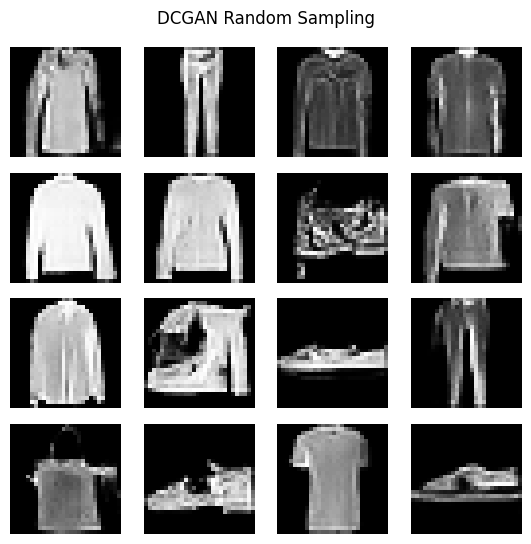

In [71]:
with torch.no_grad():
    z_16 = torch.randn(16, z_dim, device=device)
    dcgan_samples = ((dcgan_G(z_16) + 1) / 2).clamp(0, 1).squeeze(1).cpu()

fig, axes = plt.subplots(4, 4, figsize=(5.5, 5.5))

for i in range(16):
    ax = axes[i // 4, i % 4]
    ax.imshow(dcgan_samples[i], cmap="gray")
    ax.axis("off")

plt.suptitle("DCGAN Random Sampling")
plt.tight_layout()
plt.show()

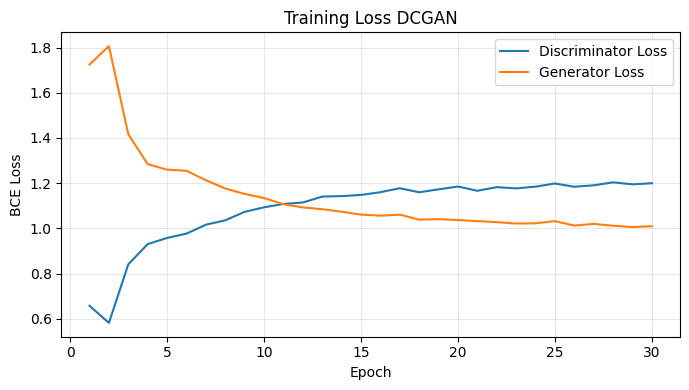

In [72]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, dcgan_epochs + 1), dcgan_d_loss, label="Discriminator Loss")
plt.plot(range(1, dcgan_epochs + 1), dcgan_g_loss, label="Generator Loss")
plt.xlabel("Epoch")
plt.ylabel("BCE Loss")
plt.title("Training Loss DCGAN")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Denoising Diffusion Probabilistic Models (DDPM)

In [75]:
T = 300
beta = torch.linspace(1e-4, 0.035, T, device=device)
alpha = 1.0 - beta
alpha_bar = torch.cumprod(alpha, dim=0)

In [76]:
def get_time_embeded(t, dim=64):
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half)
    args = t[:, None].float() * freqs[None, :]
    return torch.cat([torch.sin(args), torch.cos(args)], dim=-1)

In [77]:
def conv_block(in_c, out_c):
    return nn.Sequential(
        nn.Conv2d(in_c, out_c, 3, padding=1),
        nn.GroupNorm(8, out_c),
        nn.SiLU(),
        nn.Conv2d(out_c, out_c, 3, padding=1),
        nn.GroupNorm(8, out_c),
        nn.SiLU()
    )

In [79]:
class MiniUNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.time_mlp = nn.Sequential(
            nn.Linear(64, 128),
            nn.SiLU(),
            nn.Linear(128, 128)
        )
        self.down1 = conv_block(1, 64)
        self.pool1 = nn.Conv2d(64, 64, 4, stride=2, padding=1)
        self.down2 = conv_block(64, 128)
        self.pool2 = nn.Conv2d(128, 128, 4, stride=2, padding=1)
        self.mid = conv_block(128, 128)

        self.up2 = nn.ConvTranspose2d(128, 128, 4, stride=2, padding=1)
        self.dec2 = conv_block(256, 64)
        self.up1 = nn.ConvTranspose2d(64, 64, 4, stride=2, padding=1)
        self.dec1 = conv_block(128, 64)
        self.out = nn.Conv2d(64, 1, 1)

        self.t_d1 = nn.Linear(128, 64)
        self.t_d2 = nn.Linear(128, 128)
        self.t_mid = nn.Linear(128, 128)
        self.t_u2 = nn.Linear(128, 64)
        self.t_u1 = nn.Linear(128, 64)

    def forward(self, x, t):
        te = self.time_mlp(get_time_embeded(t, 64))

        h1 = self.down1(x) + self.t_d1(te)[:, :, None, None]
        h2 = self.down2(self.pool1(h1)) + self.t_d2(te)[:, :, None, None]
        m = self.mid(self.pool2(h2)) + self.t_mid(te)[:, :, None, None]

        u2 = torch.cat([self.up2(m), h2], dim=1)
        u2 = self.dec2(u2) + self.t_u2(te)[:, :, None, None]
        u1 = torch.cat([self.up1(u2), h1], dim=1)
        u1 = self.dec1(u1) + self.t_u1(te)[:, :, None, None]
        return self.out(u1)

ddpm_net = MiniUNet().to(device)
ddpm_opt = optim.Adam(ddpm_net.parameters(), lr=2e-4)

In [80]:
ddpm_epochs = 30
ddpm_loss = []
ddpm_times = []

for epoch in range(ddpm_epochs):
    t_start = time.time()
    ddpm_net.train()
    train_loss = 0.0

    for imgs, _ in train_loader:
        x0 = imgs.to(device) * 2 - 1
        bs = x0.size(0)
        t = torch.randint(0, T, (bs,), device=device)
        noise = torch.randn_like(x0)

        # Forward
        ab = alpha_bar[t][:, None, None, None]
        x_t = torch.sqrt(ab) * x0 + torch.sqrt(1 - ab) * noise

        ddpm_opt.zero_grad()
        pred_noise = ddpm_net(x_t, t)
        loss = mse_fn(pred_noise, noise)
        loss.backward()
        ddpm_opt.step()
        train_loss += loss.item()

    ddpm_net.eval()
    val_loss = 0.0

    with torch.no_grad():

        for imgs, _ in val_loader:
            x0 = imgs.to(device) * 2 - 1
            bs = x0.size(0)
            t = torch.randint(0, T, (bs,), device=device)
            noise = torch.randn_like(x0)
            ab = alpha_bar[t][:, None, None, None]
            x_t = torch.sqrt(ab) * x0 + torch.sqrt(1 - ab) * noise
            val_loss += mse_fn(ddpm_net(x_t, t), noise).item()

    ep_time = time.time() - t_start
    avg_train = train_loss / len(train_loader)
    avg_val = val_loss / len(val_loader)

    ddpm_loss.append(avg_train)
    ddpm_times.append(ep_time)
    print(f"Epoch {epoch+1:02d}/{ddpm_epochs} | Train MSE: {avg_train:.5f} | Val MSE: {avg_val:.5f} | Time: {ep_time:.2f}s")

Epoch 01/30 | Train MSE: 0.11791 | Val MSE: 0.08040 | Time: 44.95s
Epoch 02/30 | Train MSE: 0.07677 | Val MSE: 0.07291 | Time: 40.81s
Epoch 03/30 | Train MSE: 0.06992 | Val MSE: 0.06700 | Time: 40.37s
Epoch 04/30 | Train MSE: 0.06587 | Val MSE: 0.06482 | Time: 45.55s
Epoch 05/30 | Train MSE: 0.06398 | Val MSE: 0.06420 | Time: 47.10s
Epoch 06/30 | Train MSE: 0.06210 | Val MSE: 0.06041 | Time: 41.44s
Epoch 07/30 | Train MSE: 0.06041 | Val MSE: 0.05981 | Time: 47.06s
Epoch 08/30 | Train MSE: 0.06018 | Val MSE: 0.05775 | Time: 40.55s
Epoch 09/30 | Train MSE: 0.05923 | Val MSE: 0.06005 | Time: 40.61s
Epoch 10/30 | Train MSE: 0.05860 | Val MSE: 0.05935 | Time: 39.34s
Epoch 11/30 | Train MSE: 0.05822 | Val MSE: 0.05911 | Time: 39.91s
Epoch 12/30 | Train MSE: 0.05835 | Val MSE: 0.05689 | Time: 40.47s
Epoch 13/30 | Train MSE: 0.05693 | Val MSE: 0.05529 | Time: 40.48s
Epoch 14/30 | Train MSE: 0.05729 | Val MSE: 0.05714 | Time: 38.96s
Epoch 15/30 | Train MSE: 0.05617 | Val MSE: 0.05505 | Time: 40

In [81]:
torch.save(ddpm_net.state_dict(), "outputs/models/ddpm_net.pt")
np.save("outputs/models/ddpm_loss.npy", np.array(ddpm_loss))

In [82]:
# Reverse
def sample_ddpm(n):
    ddpm_net.eval()

    with torch.no_grad():
        x = torch.randn(n, 1, 28, 28, device=device)
        for i in reversed(range(T)):
            t = torch.full((n,), i, device=device, dtype=torch.long)
            pred = ddpm_net(x, t)
            a = alpha[i]
            ab = alpha_bar[i]
            b = beta[i]

            x = (1 / torch.sqrt(a)) * (x - ((1 - a) / torch.sqrt(1 - ab)) * pred)
            if i > 0:
                var = b * (1 - alpha_bar[i - 1]) / (1 - ab)
                x = x + torch.sqrt(var) * torch.randn_like(x)
        return (x.clamp(-1, 1) + 1) / 2

In [83]:
fid_metric.reset()

In [84]:
# Generate sample baru untuk hitung FID Score
torch.manual_seed(seed)
n_total = len(test_data)
n_done = 0

while n_done < n_total:
    bs = min(256, n_total - n_done)
    fake_img = sample_ddpm(bs)
    fake_rgb = (fake_img.clamp(0, 1) * 255).to(torch.uint8).repeat(1, 3, 1, 1)
    fid_metric.update(fake_rgb, real=False)
    n_done += bs

ddpm_fid = fid_metric.compute().item()
ddpm_avg_time = np.mean(ddpm_times)

# inference latency
_ = sample_ddpm(64)

if device.type == "cuda":
    torch.cuda.synchronize()

t0 = time.time()

for _ in range(5):
    _ = sample_ddpm(64)

if device.type == "cuda":
    torch.cuda.synchronize()

ddpm_latency = ((time.time() - t0) / 5) * 1000

print("=== Evaluasi DDPM ===")
print("Dimensi Laten: 28x28 (Dimensi Citra)")
print(f"Timesteps (T): {T}")
print(f"Training Time/Epoch: {ddpm_avg_time:.2f} detik")
print(f"Latency: {ddpm_latency:.2f} ms")
print("Test MSE: N/A (Denoising Model)")
print("Test PSNR: N/A")
print("Test SSIM: N/A")
print(f"FID Score: {ddpm_fid:.2f}")

=== Evaluasi DDPM ===
Dimensi Laten: 28x28 (Dimensi Citra)
Timesteps (T): 300
Training Time/Epoch: 40.90 detik
Latency: 4037.11 ms
Test MSE: N/A (Denoising Model)
Test PSNR: N/A
Test SSIM: N/A
FID Score: 16.09


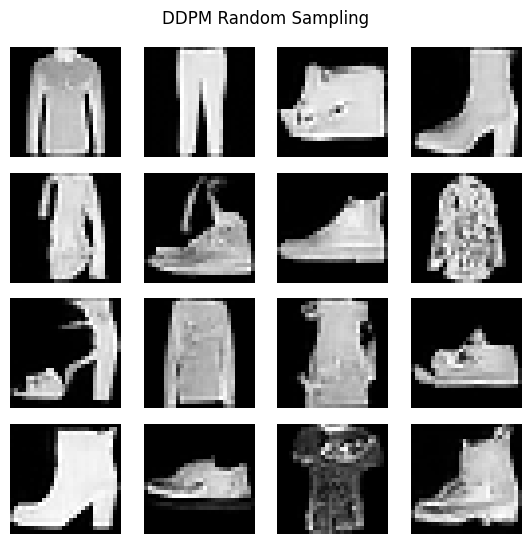

In [85]:
torch.manual_seed(seed)
ddpm_samples = sample_ddpm(16).squeeze(1).cpu()

fig, axes = plt.subplots(4, 4, figsize=(5.5, 5.5))
for i in range(16):

    ax = axes[i // 4, i % 4]
    ax.imshow(ddpm_samples[i], cmap="gray")
    ax.axis("off")

plt.suptitle(f"DDPM Random Sampling")
plt.tight_layout()
plt.show()

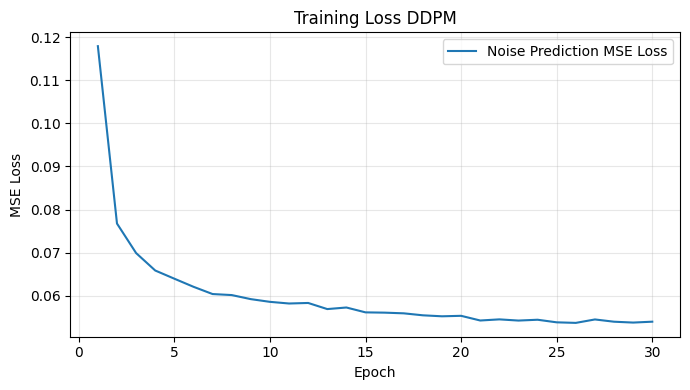

In [86]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, ddpm_epochs + 1), ddpm_loss, label="Noise Prediction MSE Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training Loss DDPM")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Hasil Eksperimen

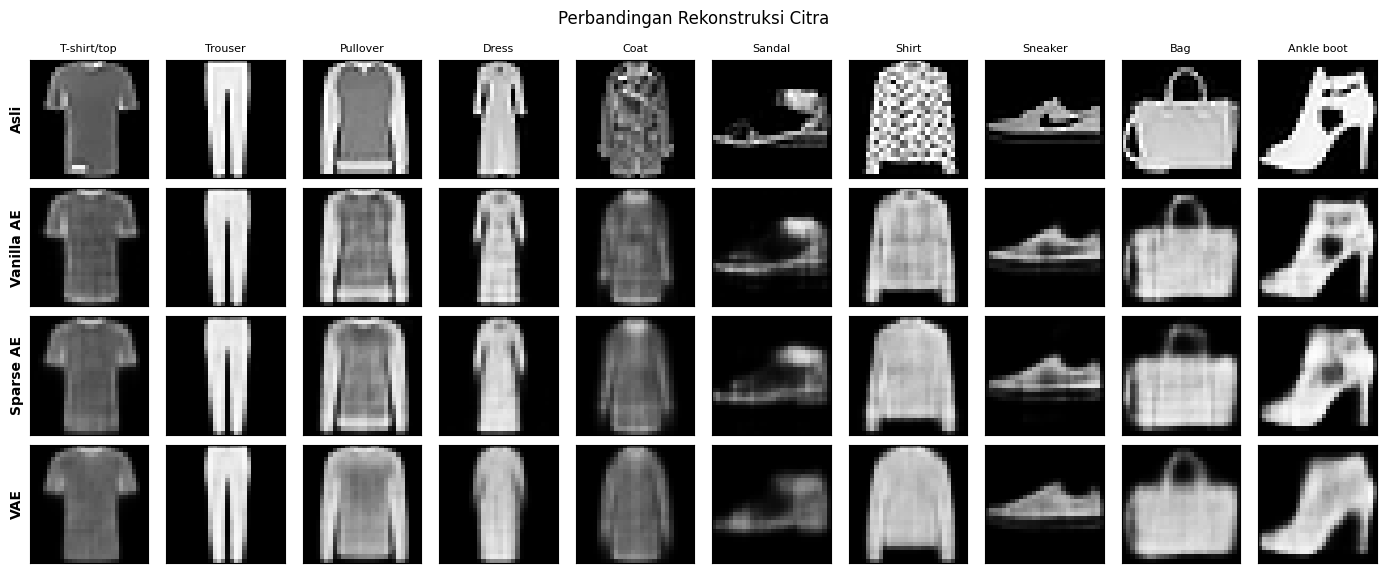

In [89]:
# Perbandingan Autoencoder

fig, axes = plt.subplots(4, 10, figsize=(14, 5.8))
rows = [sample_imgs.squeeze(1), x_ae, x_sae, x_vae]
row_names = ["Asli", "Vanilla AE", "Sparse AE", "VAE"]

for r in range(4):
    for c in range(10):
        axes[r, c].imshow(rows[r][c], cmap="gray", vmin=0, vmax=1)
        if r == 0:
            axes[r, c].set_title(classes[sample_labels[c]], fontsize=8)
        axes[r, c].set_xticks([])
        axes[r, c].set_yticks([])
    axes[r, 0].set_ylabel(row_names[r], fontsize=10, fontweight="bold")

plt.suptitle("Perbandingan Rekonstruksi Citra", fontsize=12)
plt.tight_layout()
plt.savefig("outputs/figs/rekonstruksi_ae.png", dpi=300, bbox_inches="tight")
plt.show()

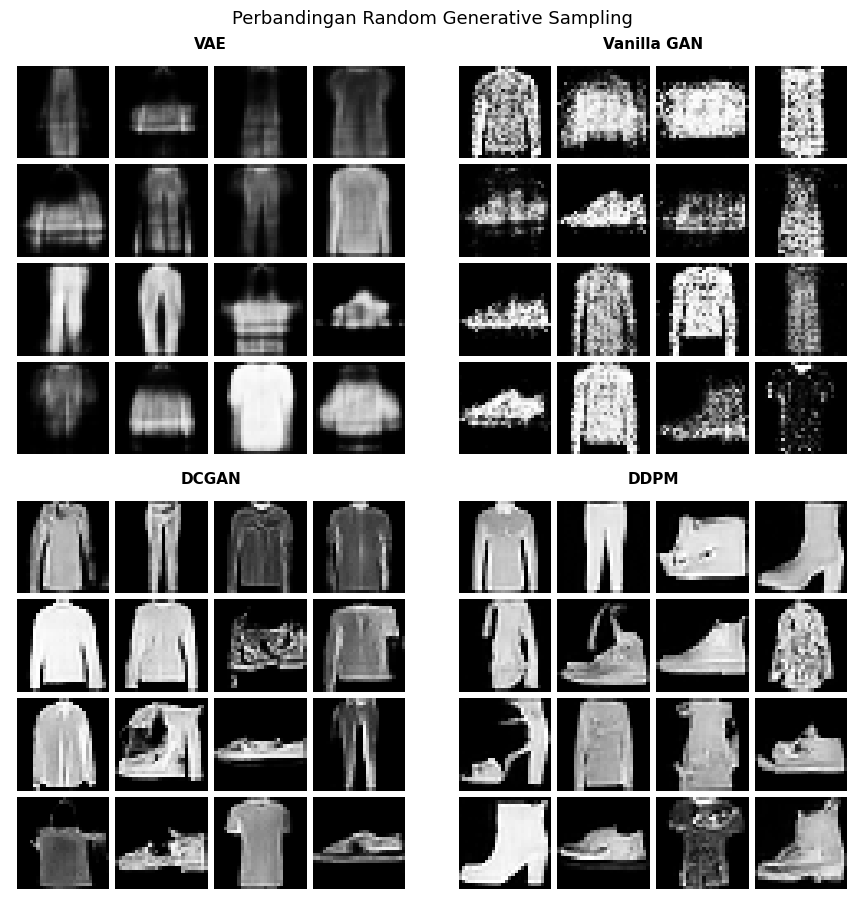

In [92]:
# Perbandingan Random Generative Sampling

from torchvision.utils import make_grid

panels = [
    ("VAE", vae_samples),
    ("Vanilla GAN", gan_samples),
    ("DCGAN", dcgan_samples),
    (f"DDPM", ddpm_samples),
]

fig, axes = plt.subplots(2, 2, figsize=(9, 9.2))

for idx, (title, imgs) in enumerate(panels):
    ax = axes[idx // 2, idx % 2]
    grid = make_grid(imgs.detach().cpu().view(16, 1, 28, 28), nrow=4, padding=2, pad_value=1.0)
    ax.imshow(grid[0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(title, fontsize=11, fontweight="bold", pad=8)
    ax.axis("off")

plt.suptitle("Perbandingan Random Generative Sampling", fontsize=13)
plt.tight_layout()
plt.savefig("outputs/figs/random_sampling.png", dpi=300, bbox_inches="tight")
plt.show()

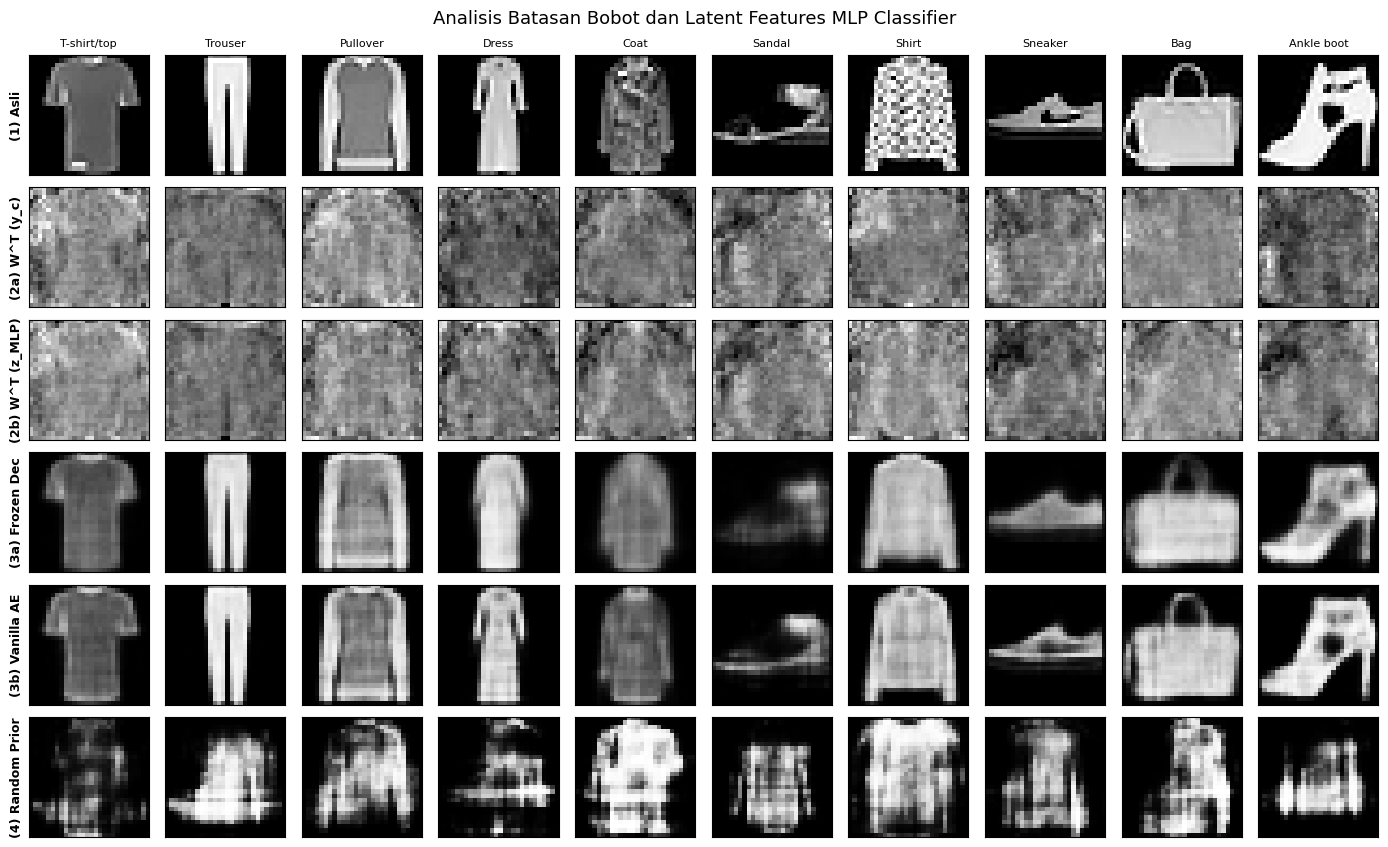

In [104]:
# Batasan Bobot dan Latent Features MLP Classifier

mlp_enc.eval()
mlp_head.eval()
frozen_dec.eval()

w_enc = [m.weight for m in mlp_enc.modules() if isinstance(m, nn.Linear)]
w_head = [m.weight for m in mlp_head.modules() if isinstance(m, nn.Linear)]
w1, w2, w3 = w_enc[0], w_enc[1], w_head[0]

z_all = []

with torch.no_grad():
    for imgs, _ in test_loader:
        z_all.append(mlp_enc(imgs.view(imgs.size(0), -1).to(device)))

z_all = torch.cat(z_all, dim=0)
mu_z = z_all.mean(dim=0)
std_z = z_all.std(dim=0)

def norm_img(t):
    t_min = t.min(dim=1, keepdim=True).values
    t_max = t.max(dim=1, keepdim=True).values
    return ((t - t_min) / (t_max - t_min + 1e-8)).view(-1, 28, 28).cpu()

with torch.no_grad():
    z_mlp = mlp_enc(x_real)

    # Proyeksi balik W^T dari vektor kelas y_c
    y_idx = torch.as_tensor(sample_labels, device=device, dtype=torch.long)
    y_c = F.one_hot(y_idx, num_classes=len(classes)).float()
    x_wt_yc = norm_img(y_c @ w3 @ w2 @ w1)

    # Proyeksi balik W^T dari fitur laten z_MLP
    x_wt_z = norm_img(z_mlp @ w2 @ w1)

    # Rekonstruksi Frozen Latent Decoder dari z_MLP
    x_frozen = frozen_dec(z_mlp).view(10, 28, 28).cpu()

    # Random Prior Sampling z_rand
    torch.manual_seed(seed)
    z_rand_mlp = mu_z + std_z * torch.randn(10, mu_z.numel(), device=device)
    x_mlp_rand = frozen_dec(z_rand_mlp).view(10, 28, 28).cpu()

fig, axes = plt.subplots(6, 10, figsize=(14, 8.6))

mlp_rows = [
    sample_imgs.squeeze(1),
    x_wt_yc,
    x_wt_z,
    x_frozen,
    x_ae,
    x_mlp_rand,
]

mlp_names = [
    "(1) Asli",
    "(2a) W^T (y_c)",
    "(2b) W^T (z_MLP)",
    "(3a) Frozen Dec",
    "(3b) Vanilla AE",
    "(4) Random Prior",
]

for r in range(6):
    for c in range(10):
        axes[r, c].imshow(mlp_rows[r][c], cmap="gray", vmin=0, vmax=1)
        if r == 0:
            axes[r, c].set_title(classes[sample_labels[c]], fontsize=8)
        axes[r, c].set_xticks([])
        axes[r, c].set_yticks([])
    axes[r, 0].set_ylabel(mlp_names[r], fontsize=9, fontweight="bold")

plt.suptitle("Analisis Batasan Bobot dan Latent Features MLP Classifier", fontsize=13)
plt.tight_layout()
plt.savefig("outputs/figs/mlp_analisis.png", dpi=300, bbox_inches="tight")
plt.show()

Kelas A: Trouser
Kelas B: Ankle boot
Confidence Vanilla GAN -> Trouser: 100.0%
Confidence Vanilla GAN -> Ankle boot: 100.0%
Confidence DCGAN -> Trouser: 100.0%
Confidence DCGAN -> Ankle boot: 100.0%


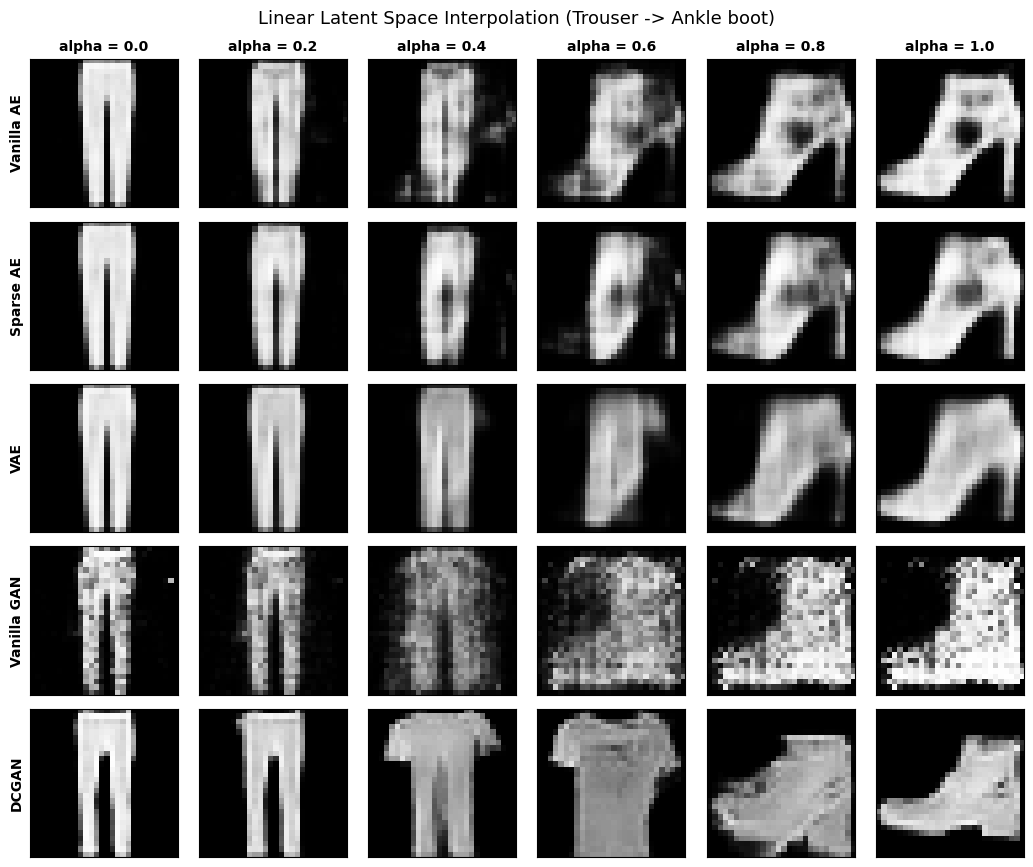

In [105]:
# Linear Latent Space Interpolation

alphas = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]

cls_a = classes.index("Trouser")
cls_b = classes.index("Ankle boot")

lbl_list = list(sample_labels) if not torch.is_tensor(sample_labels) else sample_labels.tolist()
idx_a = lbl_list.index(cls_a)
idx_b = lbl_list.index(cls_b)

x_a = x_real[idx_a:idx_a + 1]
x_b = x_real[idx_b:idx_b + 1]

def pick_gan_pair(gen_model):
    gen_model.eval()
    torch.manual_seed(seed)

    with torch.no_grad():
        z_pool = torch.randn(512, z_dim, device=device)
        imgs = (gen_model(z_pool) + 1) / 2
        imgs_flat = imgs.view(512, -1).clamp(0, 1)
        probs = F.softmax(mlp_head(mlp_enc(imgs_flat)), dim=1)
        best_a = probs[:, cls_a].argmax().item()
        best_b = probs[:, cls_b].argmax().item()
    return z_pool[best_a:best_a + 1], z_pool[best_b:best_b + 1], probs[best_a, cls_a].item(), probs[best_b, cls_b].item()

def interp_decode(z_a, z_b, dec_fn):
    out = []

    with torch.no_grad():
        for a in alphas:
            z = (1.0 - a) * z_a + a * z_b
            out.append(dec_fn(z).view(28, 28).cpu())
    return out

ae_enc.eval()
ae_dec.eval()
sae_enc.eval()
sae_dec.eval()
vae_enc.eval()
vae_mu.eval()
vae_dec.eval()

with torch.no_grad():
    ae_row = interp_decode(ae_enc(x_a), ae_enc(x_b), ae_dec)
    sae_row = interp_decode(sae_enc(x_a), sae_enc(x_b), sae_dec)
    vae_row = interp_decode(vae_mu(vae_enc(x_a)), vae_mu(vae_enc(x_b)), vae_dec)

z_gan_a, z_gan_b, p_gan_a, p_gan_b = pick_gan_pair(gan_G)
gan_row = interp_decode(z_gan_a, z_gan_b, lambda z: ((gan_G(z) + 1) / 2).clamp(0, 1))

z_dc_a, z_dc_b, p_dc_a, p_dc_b = pick_gan_pair(dcgan_G)
dcgan_row = interp_decode(z_dc_a, z_dc_b, lambda z: ((dcgan_G(z) + 1) / 2).clamp(0, 1))

print(f"Kelas A: {classes[cls_a]}")
print(f"Kelas B: {classes[cls_b]}")
print(f"Confidence Vanilla GAN -> {classes[cls_a]}: {p_gan_a*100:.1f}%")
print(f"Confidence Vanilla GAN -> {classes[cls_b]}: {p_gan_b*100:.1f}%")
print(f"Confidence DCGAN -> {classes[cls_a]}: {p_dc_a*100:.1f}%")
print(f"Confidence DCGAN -> {classes[cls_b]}: {p_dc_b*100:.1f}%")

interp_rows = [ae_row, sae_row, vae_row, gan_row, dcgan_row]
interp_names = ["Vanilla AE", "Sparse AE", "VAE", "Vanilla GAN", "DCGAN"]

fig, axes = plt.subplots(5, len(alphas), figsize=(10.5, 8.8))
for r in range(5):
    for c, a in enumerate(alphas):
        axes[r, c].imshow(interp_rows[r][c], cmap="gray", vmin=0, vmax=1)
        if r == 0:
            axes[r, c].set_title(f"alpha = {a:.1f}", fontsize=10, fontweight="bold")
        axes[r, c].set_xticks([])
        axes[r, c].set_yticks([])
    axes[r, 0].set_ylabel(interp_names[r], fontsize=10, fontweight="bold")

plt.suptitle(f"Linear Latent Space Interpolation ({classes[cls_a]} -> {classes[cls_b]})", fontsize=13)
plt.tight_layout()
plt.savefig("outputs/figs/latent_interp.png", dpi=300, bbox_inches="tight")
plt.show()

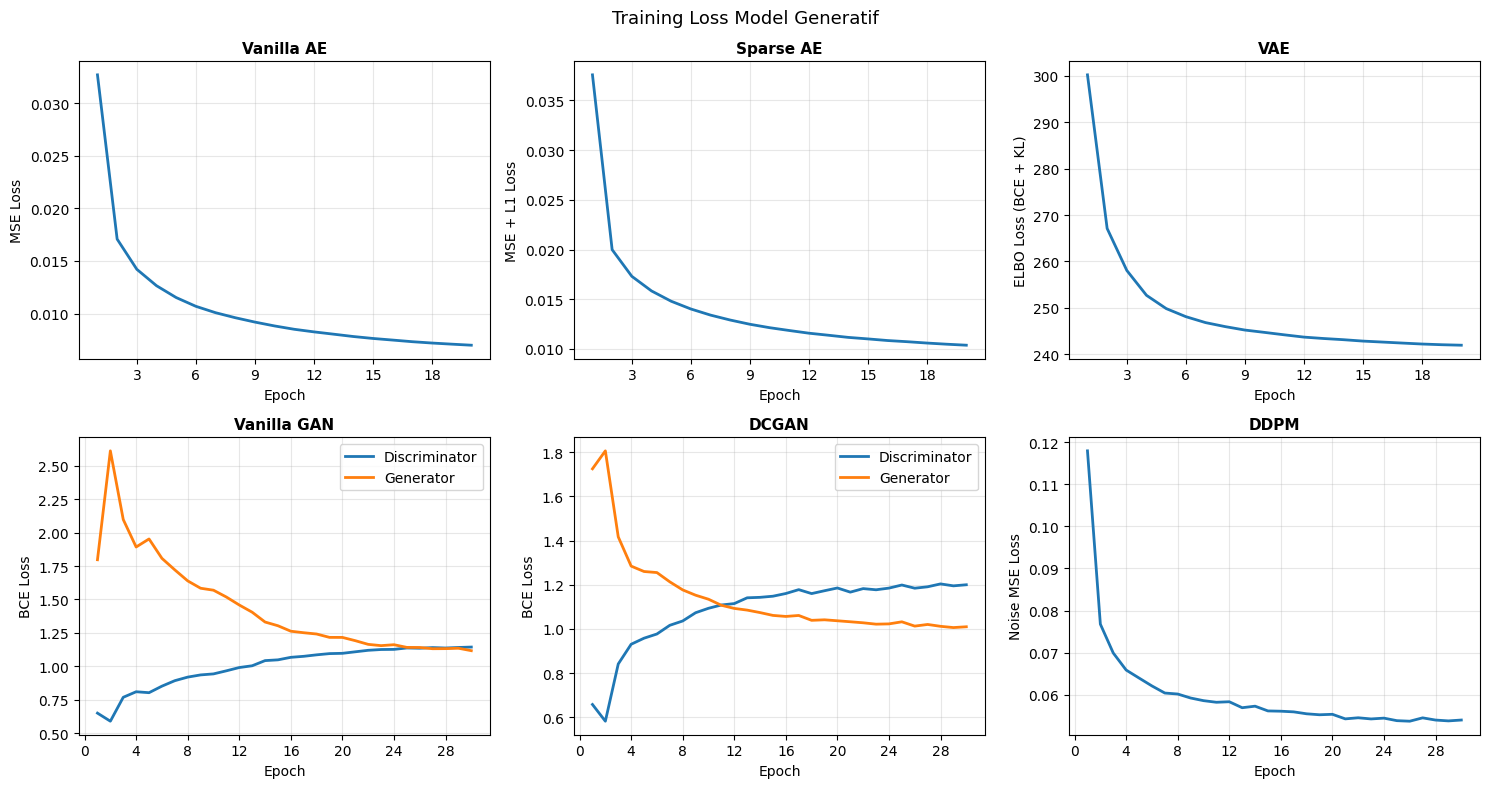

In [98]:
# Training Loss Curves

def load_loss(name):
    for suffix in ["_losses.npy", "_loss.npy"]:
        path = f"outputs/models/{name}{suffix}"
        if os.path.exists(path):
            return np.load(path)
    raise FileNotFoundError(f"'{name}' tidak ditemukan")

hist_ae = load_loss("ae")
hist_sae = load_loss("sae")
hist_vae = load_loss("vae")
hist_gan_g = load_loss("gan_g")
hist_gan_d = load_loss("gan_d")
hist_dcgan_g = load_loss("dcgan_g")
hist_dcgan_d = load_loss("dcgan_d")
hist_ddpm = load_loss("ddpm")

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# Autoencoder
single_plots = [
    (axes[0, 0], hist_ae, "Vanilla AE", "MSE Loss"),
    (axes[0, 1], hist_sae, "Sparse AE", "MSE + L1 Loss"),
    (axes[0, 2], hist_vae, "VAE", "ELBO Loss (BCE + KL)"),
]

for ax, data, title, ylabel in single_plots:
    ep = range(1, len(data) + 1)
    ax.plot(ep, data, linewidth=2)
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(True, alpha=0.3)

# GAN, DCGAN, dan DDPM
gan_plots = [
    (axes[1, 0], hist_gan_d, hist_gan_g, "Vanilla GAN"),
    (axes[1, 1], hist_dcgan_d, hist_dcgan_g, "DCGAN"),
]

for ax, d_data, g_data, title in gan_plots:
    ep = range(1, len(d_data) + 1)
    ax.plot(ep, d_data, label="Discriminator", linewidth=2)
    ax.plot(ep, g_data, label="Generator", linewidth=2)
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("BCE Loss")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.legend()
    ax.grid(True, alpha=0.3)

ep_ddpm = range(1, len(hist_ddpm) + 1)
axes[1, 2].plot(ep_ddpm, hist_ddpm, linewidth=2)
axes[1, 2].set_title(f"DDPM", fontsize=11, fontweight="bold")
axes[1, 2].set_xlabel("Epoch")
axes[1, 2].set_ylabel("Noise MSE Loss")
axes[1, 2].xaxis.set_major_locator(MaxNLocator(integer=True))
axes[1, 2].grid(True, alpha=0.3)

plt.suptitle("Training Loss Model Generatif", fontsize=13)
plt.tight_layout()
plt.savefig("outputs/figs/kurva_loss.png", dpi=300, bbox_inches="tight")
plt.show()

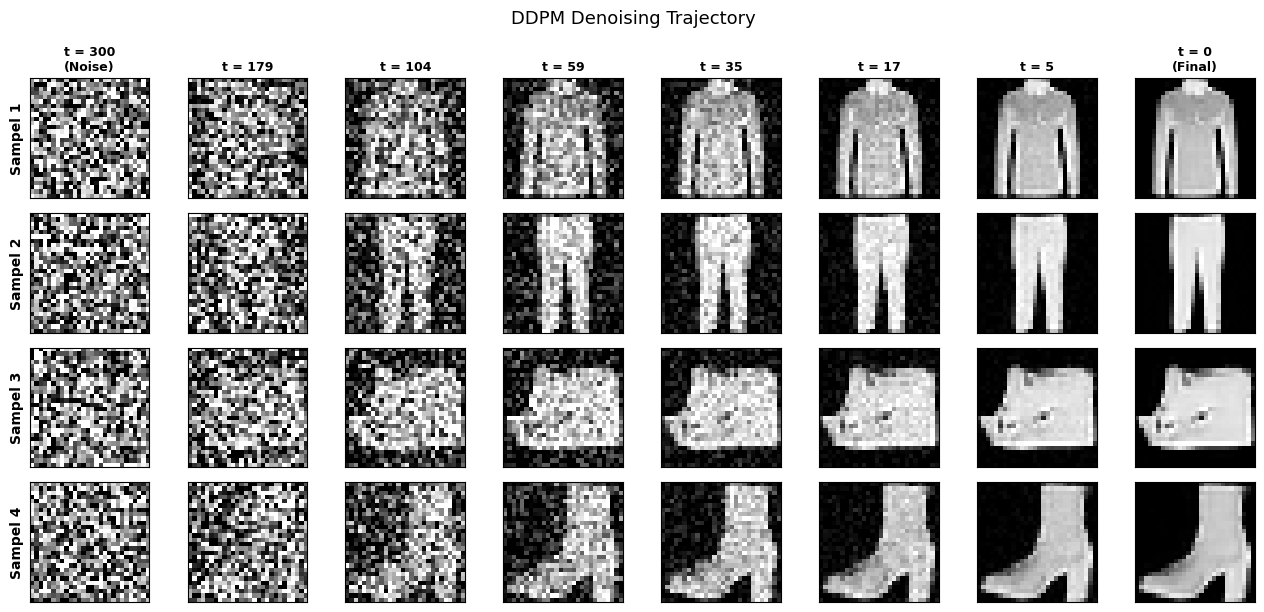

In [103]:
# DDPM Denoising Trajectory

torch.manual_seed(seed)
n_traj = 4
x = torch.randn(n_traj, 1, 28, 28, device=device)

ratio = [0.60, 0.35, 0.20, 0.12, 0.06, 0.02, 0.0]
snap_steps = sorted({int(r * (T - 1)) for r in ratio}, reverse=True)

traj_imgs = [((x.clamp(-1, 1) + 1) / 2).squeeze(1).cpu()]
traj_labels = [f"t = {T}\n(Noise)"]

ddpm_net.eval()
with torch.no_grad():
    for i in reversed(range(T)):
        t = torch.full((n_traj,), i, device=device, dtype=torch.long)
        pred = ddpm_net(x, t)
        a = alpha[i]
        ab = alpha_bar[i]
        b = beta[i]

        x = (1 / torch.sqrt(a)) * (x - ((1 - a) / torch.sqrt(1 - ab)) * pred)
        if i > 0:
            var = b * (1 - alpha_bar[i - 1]) / (1 - ab)
            x = x + torch.sqrt(var) * torch.randn_like(x)

        if i in snap_steps:
            traj_imgs.append(((x.clamp(-1, 1) + 1) / 2).squeeze(1).cpu())
            label = "t = 0\n(Final)" if i == 0 else f"t = {i}"
            traj_labels.append(label)

n_cols = len(traj_imgs)
fig, axes = plt.subplots(n_traj, n_cols, figsize=(13, 6.2))

for r in range(n_traj):
    for c in range(n_cols):
        axes[r, c].imshow(traj_imgs[c][r], cmap="gray", vmin=0, vmax=1)
        if r == 0:
            axes[r, c].set_title(traj_labels[c], fontsize=9, fontweight="bold")
        axes[r, c].set_xticks([])
        axes[r, c].set_yticks([])
    axes[r, 0].set_ylabel(f"Sampel {r+1}", fontsize=10, fontweight="bold")

plt.suptitle("DDPM Denoising Trajectory", fontsize=13)
plt.tight_layout()
plt.savefig("outputs/figs/ddpm_trajectory.png", dpi=300, bbox_inches="tight")
plt.show()